In [ ]:

import kagglehub

# Download latest version
path = kagglehub.dataset_download("datasetengineer/logistics-vehicle-maintenance-history-dataset")

import sys
sys.path.append(r'C:\Users\Toti\Downloads\TOTI')
#sys.path.append(r'C:\Users\usuario\Downloads\archive (3)')
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import utilities as utils
import os

#ruta = "C:/Users/Toti/.cache/kagglehub/datasets/datasetengineer/logistics-vehicle-maintenance-history-dataset/versions/3/revised_logistics_dataset_V2.csv"


df = pd.read_csv(os.path.join(path, "revised_logistics_dataset_V2.csv"))

df = df.sample(frac=1.0, random_state=0).reset_index(drop=True)

C:\Users\Toti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Vehicle_ID              250000 non-null  float64
 1   Make_and_Model          250000 non-null  str    
 2   Year_of_Manufacture     250000 non-null  float64
 3   Vehicle_Type            250000 non-null  str    
 4   Usage_Hours             250000 non-null  float64
 5   Route_Info              250000 non-null  str    
 6   Load_Capacity           250000 non-null  float64
 7   Actual_Load             250000 non-null  float64
 8   Last_Maintenance_Date   250000 non-null  str    
 9   Maintenance_Type        250000 non-null  str    
 10  Maintenance_Cost        250000 non-null  float64
 11  Engine_Temperature      250000 non-null  float64
 12  Tire_Pressure           250000 non-null  float64
 13  Fuel_Consumption        250000 non-null  float64
 14  Battery_Status          250000 

In [ ]:
columnas_a_eliminar = [
    "Vehicle_ID",
    "Anomalies_Detected",  # posible leakage
    "Make_and_Model",      # alta cardinalidad
    "Predictive_Score",    # posible leakage
    "Route_Info"           # se repite con Road_Conditions
]

df = df.drop(columns = columnas_a_eliminar, errors="ignore")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Year_of_Manufacture     250000 non-null  float64
 1   Vehicle_Type            250000 non-null  str    
 2   Usage_Hours             250000 non-null  float64
 3   Load_Capacity           250000 non-null  float64
 4   Actual_Load             250000 non-null  float64
 5   Last_Maintenance_Date   250000 non-null  str    
 6   Maintenance_Type        250000 non-null  str    
 7   Maintenance_Cost        250000 non-null  float64
 8   Engine_Temperature      250000 non-null  float64
 9   Tire_Pressure           250000 non-null  float64
 10  Fuel_Consumption        250000 non-null  float64
 11  Battery_Status          250000 non-null  float64
 12  Vibration_Levels        250000 non-null  float64
 13  Oil_Quality             250000 non-null  float64
 14  Brake_Condition         250000 

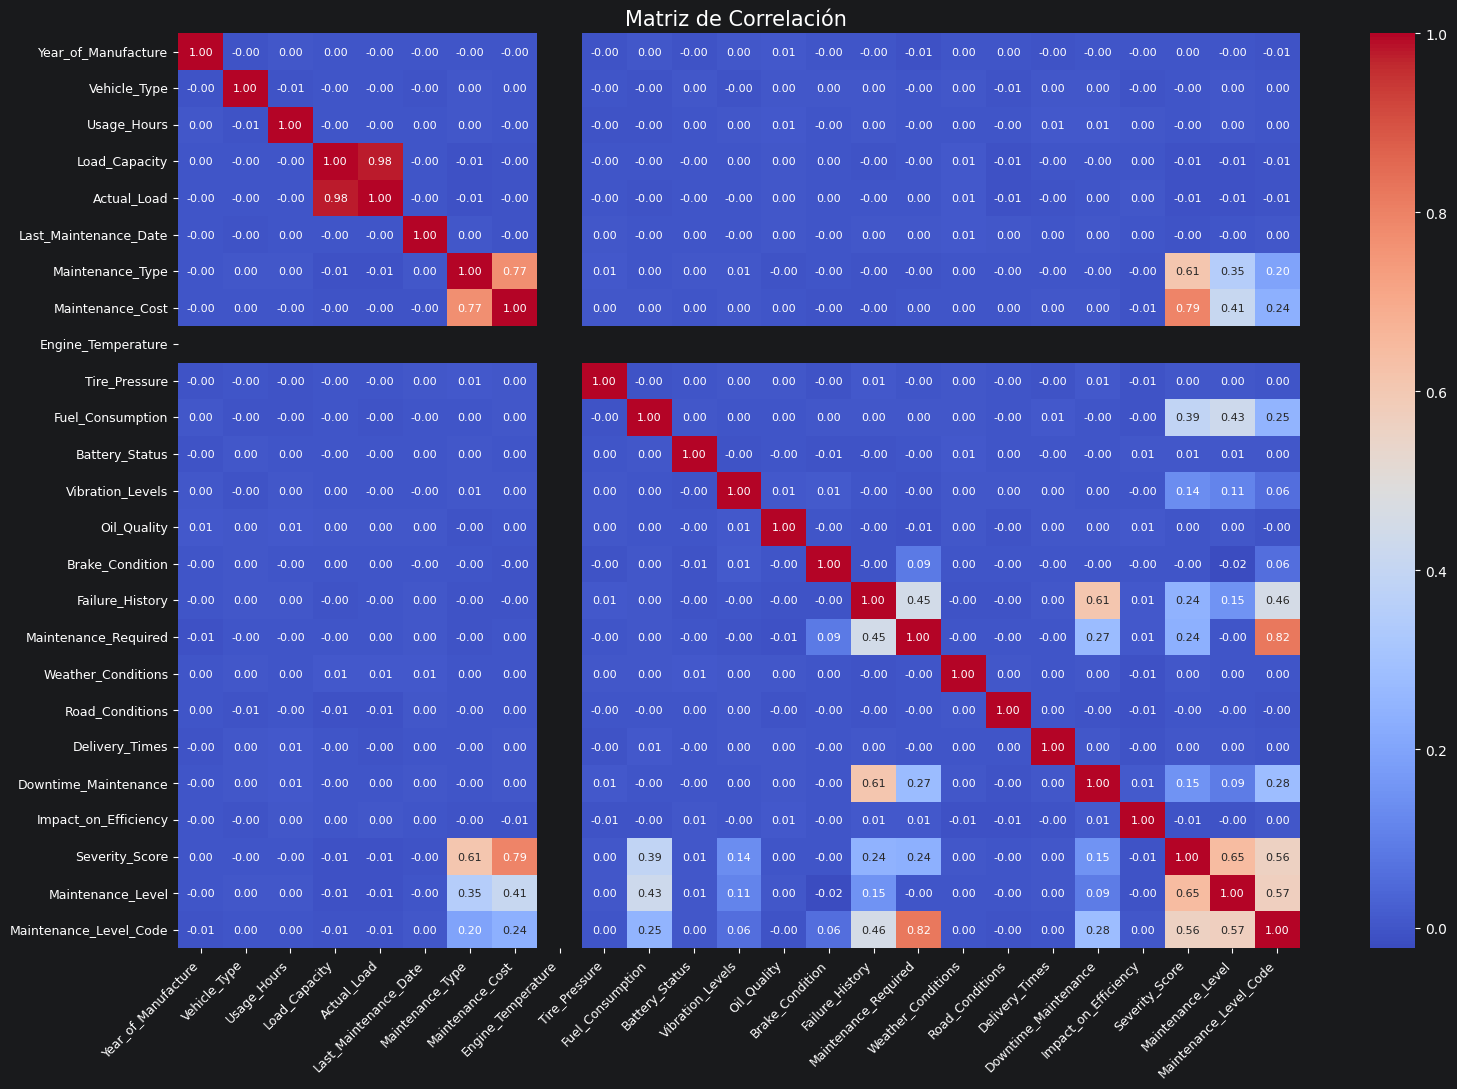

In [ ]:
Route_map = {
    'Highway': 1 , #menor desgaste
    'Rural': 2,
    'Urban': 3 #max desgaste
}
Maintenance_map = {
    'Oil Change': 1 ,
    'Tire Rotation': 2,
    'Engine Overhaul': 3
}
Brake_map = {
    'Good': 1,
    'Poor': 2,
    'Fair':3
}
Weather_map = {
    'Clear': 1,
    'Rainy': 2,
    'Windy': 3,
    'Snowy': 4
}
Maintenance_Level_map = {
    'Minor': 1,
    'Normal': 2,
    'Major': 3
}


#df['Last_Maintenance_Date'] = pd.to_datetime(df['Last_Maintenance_Date'])

df["Last_Maintenance_Date"] = pd.to_datetime(df["Last_Maintenance_Date"])
df["Last_Maintenance_Date"] = (df["Last_Maintenance_Date"] - df["Last_Maintenance_Date"].min()).dt.days + 1

df['Road_Conditions'] = df['Road_Conditions'].map(Route_map)
df['Maintenance_Type'] = df['Maintenance_Type'].map(Maintenance_map)
df['Brake_Condition'] = df['Brake_Condition'].map(Brake_map)
df['Weather_Conditions'] = df['Weather_Conditions'].map(Weather_map)
df['Maintenance_Level'] = df['Maintenance_Level'].map(Maintenance_Level_map)
df['Vehicle_Type'] = df['Vehicle_Type'].map({'Truck': 0, 'Van': 1})


df = df.dropna(subset=["Weather_Conditions", "Maintenance_Level"])


matriz_corr = df.corr(numeric_only=True)

plt.figure(figsize=(16, 11))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    annot_kws={"size": 8}
)

plt.title("Matriz de Correlación ", fontsize=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Year_of_Manufacture     250000 non-null  float64
 1   Vehicle_Type            250000 non-null  int64  
 2   Usage_Hours             250000 non-null  float64
 3   Load_Capacity           250000 non-null  float64
 4   Actual_Load             250000 non-null  float64
 5   Last_Maintenance_Date   250000 non-null  int64  
 6   Maintenance_Type        250000 non-null  int64  
 7   Maintenance_Cost        250000 non-null  float64
 8   Engine_Temperature      250000 non-null  float64
 9   Tire_Pressure           250000 non-null  float64
 10  Fuel_Consumption        250000 non-null  float64
 11  Battery_Status          250000 non-null  float64
 12  Vibration_Levels        250000 non-null  float64
 13  Oil_Quality             250000 non-null  float64
 14  Brake_Condition         250000 

In [ ]:
X = df.drop(columns=['Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost', 'Maintenance_Required']).values
y = df['Maintenance_Level_Code'].values

X_train, X_test, y_train, y_test = utils.train_test_split(
    X,
    y,
    test_size=0.2,
    seed=67
)

X_train_std, mean, std = utils.standardize(X_train)
X_test_std = (X_test - mean) / std



In [ ]:
resultados_class = {}
tiempos_class = {}
precision_recall_f1_class = {}

X_train_tree = np.round(X_train_std, 1)
X_test_tree = np.round(X_test_std, 1)


modelos_cat = {
    "Árbol de Decisión": utils.DecisionTreeClassifier(max_depth=10, min_samples_split=5),
    "KNN": utils.KNNClassifier(n_neighbors=5),
    "Naive Bayes": utils.GaussianNaiveBayes(var_smoothing=1e-10),
    "Bosques Aleatorios": utils.RandomForestClassifier(),
    "Redes Neuronales": utils.NeuralNetworkMulti(hidden_size=16, learning_rate=0.5, n_iterations=1000)
}

for nombre, modelo in modelos_cat.items():

    X_fit = X_train_tree if nombre in ("Árbol de Decisión", "Bosques Aleatorios") else X_train_std
    X_pred = X_test_tree if nombre in ("Árbol de Decisión", "Bosques Aleatorios") else X_test_std

    inicio = time.perf_counter()
    modelo.fit(X_fit, y_train)
    y_pred = np.asarray(modelo.predict(X_pred))

    precision = utils.accuracy(y_test, y_pred)
    prec, rec, f1 = utils.precision_recall_f1(y_test, y_pred)

    resultados_class[nombre] = precision
    precision_recall_f1_class[nombre] = f1

    fin = time.perf_counter()
    tiempo_total = fin - inicio
    tiempos_class[nombre] = tiempo_total

    print(f"{nombre}: Exactitud: {precision  * 100:.2f}% | F1-Score: {f1:.4f} | Tiempo: {tiempo_total:.4f} seg")


Árbol de Decisión: Exactitud: 89.94% | F1-Score: 0.9364 | Tiempo: 48.3391 seg
KNN: Exactitud: 82.85% | F1-Score: 0.9094 | Tiempo: 1490.4220 seg
Naive Bayes: Exactitud: 59.58% | F1-Score: 0.5890 | Tiempo: 0.0908 seg
Bosques Aleatorios: Exactitud: 86.19% | F1-Score: 0.8956 | Tiempo: 892.1291 seg
Redes Neuronales: Exactitud: 89.72% | F1-Score: 0.9319 | Tiempo: 108.5134 seg


In [ ]:
resultados_bin = {}
tiempos_bin = {}
precision_recall_f1_bin = {}

X_2 = df.drop(columns=[ 'Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost', 'Maintenance_Required']).values
y_2 = df['Maintenance_Required'].values

X_train2, X_test2, y_train2, y_test2 = utils.train_test_split(
    X_2,
    y_2,
    test_size=0.2,
    seed=67
)

X_train_std2, mean, std = utils.standardize(X_train2)
X_test_std2 = (X_test2 - mean) / std



modelos_bin = {
    "SVM": utils.LinearSVM(learning_rate=0.01, n_iterations=2000, C=100.0),
    "Redes Neuronales": utils.NeuralNetwork(hidden_size=16, learning_rate=0.5, n_iterations=1000),
    "Regresión Logística": utils.LogisticRegression(learning_rate=0.1, n_iterations=2000),
}

for nombre, modelo in modelos_bin.items():
    inicio = time.perf_counter()
    modelo.fit(X_train_std2, y_train2)
    y_pred2 = modelo.predict(X_test_std2)

    precision = utils.accuracy(y_test2, y_pred2)
    prec, rec, f1 = utils.precision_recall_f1(y_test2, y_pred2)

    resultados_bin[nombre] = precision
    precision_recall_f1_bin[nombre] = f1
    fin = time.perf_counter()
    tiempo_total = fin - inicio
    tiempos_bin[nombre] = tiempo_total

    print(f"{nombre}: Exactitud: {precision  * 100:.2f}% | F1-Score: {f1:.4f} | Tiempo: {tiempo_total:.4f} seg")

SVM: Exactitud: 80.14% | F1-Score: 0.8855 | Tiempo: 8.6651 seg
Redes Neuronales: Exactitud: 90.46% | F1-Score: 0.9382 | Tiempo: 92.6982 seg
Regresión Logística: Exactitud: 79.98% | F1-Score: 0.8763 | Tiempo: 10.8897 seg


In [ ]:
X_reg = df.drop(columns=['Maintenance_Cost', 'Maintenance_Level']).values
y_reg = df['Maintenance_Cost'].values

X_train_reg, X_test_reg, y_train_reg, y_test_reg = utils.train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    seed=67
)

X_train_reg_std, mean_r, std_r = utils.standardize(X_train_reg)
X_test_reg_std = (X_test_reg - mean_r) / std_r

pca_reg = utils.PCA(n_components=3)
PC_train_reg = pca_reg.fit_transform(X_train_reg_std)
PC_test_reg = pca_reg.transform(X_test_reg_std)

modelos_regresion = {
    "Regresión Lineal Simple": utils.LinearRegression(learning_rate=0.001, n_iterations=2000),
    "Regresión Lineal Múltiple": utils.MultipleLinearRegression(),
    "Árbol de Regresión": utils.RegressionTree(max_depth=10, min_samples_split=5),
    "Gradient Boosting Regressor": utils.GradientBoostingRegressor(n_estimators=50, max_depth=8),
    "Redes Neuronales": utils.NeuralNetworkReg(hidden_size=16, learning_rate=0.05, n_iterations=1000)
}

resultados_mse = {}
tiempos_regresion = {}

for nombre, modelo in modelos_regresion.items():
    inicio = time.perf_counter()

    arbol = nombre in ("Árbol de Regresión", "Gradient Boosting Regressor")
    X_fit = np.round(PC_train_reg, 1) if arbol else PC_train_reg
    X_pred = np.round(PC_test_reg, 1) if arbol else PC_test_reg


    modelo.fit(X_fit, y_train_reg)
    y_pred_reg = modelo.predict(X_pred)


    mae = utils.mean_absolute_error(y_test_reg, y_pred_reg)

    Rmse = np.sqrt(utils.mean_squared_error(y_test_reg, y_pred_reg))

    fin = time.perf_counter()
    tiempo_total = fin - inicio

    resultados_mse[nombre] = Rmse
    tiempos_regresion[nombre] = tiempo_total

    print(f"{nombre}: RMSE: {Rmse:.4f} | MAE: {mae:.4f} | Tiempo: {tiempo_total:.4f} seg")

Regresión Lineal Simple: RMSE: 1061.7676 | MAE: 817.4804 | Tiempo: 20.5292 seg
Regresión Lineal Múltiple: RMSE: 1061.5389 | MAE: 818.0009 | Tiempo: 0.0066 seg
Árbol de Regresión: RMSE: 720.4096 | MAE: 384.8095 | Tiempo: 9.4528 seg
Gradient Boosting Regressor: RMSE: 698.2369 | MAE: 377.5274 | Tiempo: 389.0678 seg
Redes Neuronales: RMSE: 800.8975 | MAE: 478.9440 | Tiempo: 84.8558 seg


In [ ]:
def medir(f, rep=3):
    ts = []
    for _ in range(rep):
        inicio = time.perf_counter()
        f()
        ts.append(time.perf_counter() - inicio)
    return float(np.median(ts))


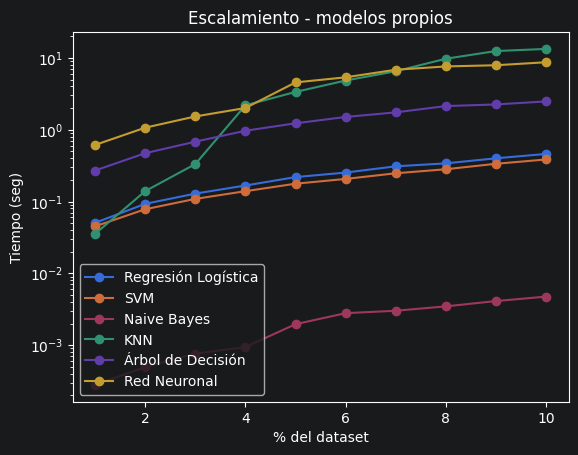

In [ ]:
N_TOTAL = 250000
porcentajes = range(1, 11)
X_all = df.drop(columns=['Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost', 'Maintenance_Required']).values
y_all = df['Maintenance_Required'].values

modelos = {
    "Regresión Logística": utils.LogisticRegression(learning_rate=0.1, n_iterations=2000),
    "SVM": utils.LinearSVM(learning_rate=0.01, n_iterations=2000, C=100.0),
    "Naive Bayes": utils.GaussianNaiveBayes(var_smoothing=1e-10),
    "KNN": utils.KNNClassifier(n_neighbors=5),
    "Árbol de Decisión": utils.DecisionTreeClassifier(max_depth=10, min_samples_split=5),
    "Red Neuronal": utils.NeuralNetwork(hidden_size=16, learning_rate=0.5, n_iterations=1000),
}
tiempos = {nombre: [] for nombre in modelos}

X_esc, _, _ = utils.standardize(X_all)

for p in porcentajes:
    n = int(N_TOTAL * p / 100)
    X_tr, X_te, y_tr, y_te = utils.train_test_split(X_esc[:n], y_all[:n], test_size=0.2, seed=0)
    for nombre, modelo in modelos.items():
        A, B = (np.round(X_tr, 1), np.round(X_te, 1)) if nombre == "Árbol de Decisión" else (X_tr, X_te)
        tiempos[nombre].append(medir(lambda: (modelo.fit(A, y_tr), modelo.predict(B))))

for nombre, t in tiempos.items():
    plt.plot(porcentajes, t, marker='o', label=nombre)
plt.yscale('log')
plt.xlabel('% del dataset')
plt.ylabel('Tiempo (seg)')
plt.title('Escalamiento - modelos propios')
plt.legend()
plt.show()

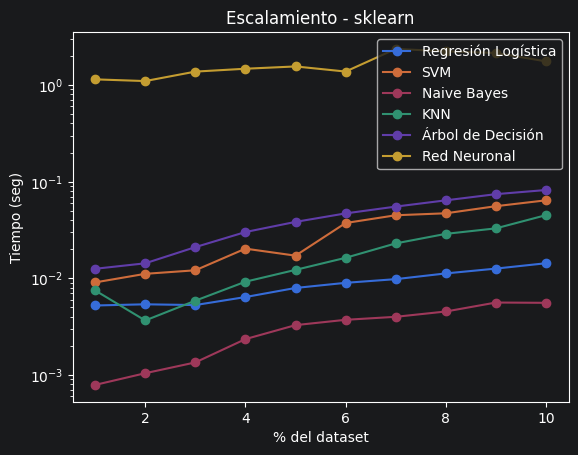

In [ ]:
from sklearn import tree, neighbors, naive_bayes, ensemble, neural_network, linear_model, svm
from sklearn.model_selection import train_test_split as sk_split
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)


modelos_sk = {
    "Regresión Logística": linear_model.LogisticRegression(max_iter=2000),
    "SVM": svm.LinearSVC(C=100.0),
    "Naive Bayes": naive_bayes.GaussianNB(),
    "KNN": neighbors.KNeighborsClassifier(n_neighbors=5),
    "Árbol de Decisión": tree.DecisionTreeClassifier(max_depth=10, min_samples_split=5),
    "Red Neuronal": neural_network.MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000),
}
tiempos_sk = {nombre: [] for nombre in modelos_sk}

X_esc = StandardScaler().fit_transform(X_all)

for p in porcentajes:
    n = int(N_TOTAL * p / 100)
    X_tr, X_te, y_tr, y_te = sk_split(X_esc[:n], y_all[:n], test_size=0.2, random_state=0)
    for nombre, modelo in modelos_sk.items():
        tiempos_sk[nombre].append(medir(lambda: (modelo.fit(X_tr, y_tr), modelo.predict(X_te))))

for nombre, t in tiempos_sk.items():
    plt.plot(porcentajes, t, marker='o', label=nombre)
plt.yscale('log')
plt.xlabel('% del dataset')
plt.ylabel('Tiempo (seg)')
plt.title('Escalamiento - sklearn')
plt.legend()
plt.show()

In [ ]:
resultados_class_sklearn = {}
tiempos_class_sklearn = {}
precision_recall_f1_class_sklearn = {}

X_class_sklearn = df.drop(columns=['Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost', 'Maintenance_Required']).values
y_class_sklearn = df['Maintenance_Level_Code'].values

X_train_sklearn, X_test_sklearn, y_train_sklearn, y_test_sklearn = utils.train_test_split(
    X_class_sklearn,
    y_class_sklearn,
    test_size=0.2,
    seed=67
)

X_train_std_sklearn, mean_sklearn, std_sklearn = utils.standardize(X_train_sklearn)
X_test_std_sklearn = (X_test_sklearn - mean_sklearn) / std_sklearn

X_train_tree_sklearn = np.round(X_train_std_sklearn, 1)
X_test_tree_sklearn = np.round(X_test_std_sklearn, 1)

modelos_cat_sklearn = {
    "Árbol de Decisión": tree.DecisionTreeClassifier(max_depth=10, min_samples_split=5),
    "KNN": neighbors.KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": naive_bayes.GaussianNB(var_smoothing=1e-10),
    #  renombra n_estimators
    "Bosques Aleatorios": ensemble.RandomForestClassifier(n_estimators=25, max_depth=5),
    "Redes Neuronales": neural_network.MLPClassifier(
        hidden_layer_sizes=(16,), activation="tanh",
        learning_rate_init=0.5, max_iter=1000, n_iter_no_change=1000)
}

for nombre, modelo in modelos_cat_sklearn.items():

    X_fit = X_train_tree_sklearn if nombre in ("Árbol de Decisión", "Bosques Aleatorios") else X_train_std_sklearn
    X_pred = X_test_tree_sklearn if nombre in ("Árbol de Decisión", "Bosques Aleatorios") else X_test_std_sklearn

    inicio = time.perf_counter()
    modelo.fit(X_fit, y_train_sklearn)
    y_pred = np.asarray(modelo.predict(X_pred))

    precision = utils.accuracy(y_test_sklearn, y_pred)
    prec, rec, f1 = utils.precision_recall_f1(y_test_sklearn, y_pred)

    resultados_class_sklearn[nombre] = precision
    precision_recall_f1_class_sklearn[nombre] = f1

    fin = time.perf_counter()
    tiempo_total = fin - inicio
    tiempos_class_sklearn[nombre] = tiempo_total

    print(f"{nombre}: Exactitud: {precision  * 100:.2f}% | F1-Score: {f1:.4f} | Tiempo: {tiempo_total:.4f} seg")

Árbol de Decisión: Exactitud: 89.93% | F1-Score: 0.9364 | Tiempo: 0.4618 seg
KNN: Exactitud: 82.44% | F1-Score: 0.9064 | Tiempo: 2.9134 seg
Naive Bayes: Exactitud: 59.58% | F1-Score: 0.5890 | Tiempo: 0.1177 seg
Bosques Aleatorios: Exactitud: 82.79% | F1-Score: 0.8713 | Tiempo: 1.7382 seg
Redes Neuronales: Exactitud: 88.31% | F1-Score: 0.9342 | Tiempo: 473.8651 seg


In [ ]:
resultados_bin_sklearn = {}
tiempos_bin_sklearn = {}
precision_recall_f1_bin_sklearn = {}

X_2_sklearn = df.drop(columns=[ 'Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost', 'Maintenance_Required']).values
y_2_sklearn = df['Maintenance_Required'].values

X_train2_sklearn, X_test2_sklearn, y_train2_sklearn, y_test2_sklearn = utils.train_test_split(
    X_2_sklearn,
    y_2_sklearn,
    test_size=0.2,
    seed=67
)

X_train_std2_sklearn, mean2_sklearn, std2_sklearn = utils.standardize(X_train2_sklearn)
X_test_std2_sklearn = (X_test2_sklearn - mean2_sklearn) / std2_sklearn

modelos_bin_sklearn = {
    "SVM": svm.LinearSVC(),
    "Redes Neuronales": neural_network.MLPClassifier(
        hidden_layer_sizes=(16,), activation="tanh",
        learning_rate_init=0.5, max_iter=1000, n_iter_no_change=1000),
    "Regresión Logística": linear_model.LogisticRegression(),
}
for nombre, modelo in modelos_bin_sklearn.items():
    inicio = time.perf_counter()
    modelo.fit(X_train_std2_sklearn, y_train2_sklearn)
    y_pred2 = modelo.predict(X_test_std2_sklearn)

    precision = utils.accuracy(y_test2_sklearn, y_pred2)
    prec, rec, f1 = utils.precision_recall_f1(y_test2_sklearn, y_pred2)

    resultados_bin_sklearn[nombre] = precision
    precision_recall_f1_bin_sklearn[nombre] = f1
    fin = time.perf_counter()
    tiempo_total = fin - inicio
    tiempos_bin_sklearn[nombre] = tiempo_total

    print(f"{nombre}: Exactitud: {precision  * 100:.2f}% | F1-Score: {f1:.4f} | Tiempo: {tiempo_total:.4f} seg")

SVM: Exactitud: 79.58% | F1-Score: 0.8741 | Tiempo: 1.5589 seg
Redes Neuronales: Exactitud: 87.75% | F1-Score: 0.9259 | Tiempo: 502.1294 seg
Regresión Logística: Exactitud: 79.99% | F1-Score: 0.8763 | Tiempo: 0.1483 seg


In [ ]:
X_reg_sklearn = df.drop(columns=['Maintenance_Cost', 'Maintenance_Level']).values
y_reg_sklearn = df['Maintenance_Cost'].values

X_train_reg_sklearn, X_test_reg_sklearn, y_train_reg_sklearn, y_test_reg_sklearn = utils.train_test_split(
    X_reg_sklearn,
    y_reg_sklearn,
    test_size=0.2,
    seed=67
)

X_train_reg_std_sklearn, mean_r_sklearn, std_r_sklearn = utils.standardize(X_train_reg_sklearn)
X_test_reg_std_sklearn = (X_test_reg_sklearn - mean_r_sklearn) / std_r_sklearn

pca_reg_sklearn = PCA(n_components=3)
PC_train_reg_sklearn = pca_reg_sklearn.fit_transform(X_train_reg_std_sklearn)
PC_test_reg_sklearn = pca_reg_sklearn.transform(X_test_reg_std_sklearn)

modelos_regresion_sklearn = {
    "Regresión Lineal Simple": linear_model.LinearRegression(),
    "Regresión Lineal Múltiple": linear_model.LinearRegression(),
    "Árbol de Regresión": tree.DecisionTreeRegressor(max_depth=10, min_samples_split=5),
    "Gradient Boosting Regressor": ensemble.GradientBoostingRegressor(n_estimators=50, max_depth=8, learning_rate=0.1),
    # lr=0.1 equivale a 0.05; sklearn usa MSE/2; y estandarizada
    "Redes Neuronales": TransformedTargetRegressor(
        regressor=neural_network.MLPRegressor(
            hidden_layer_sizes=(16,), activation="tanh",
            learning_rate_init=0.1, max_iter=1000),
        transformer=StandardScaler())
}

resultados_mse_sklearn = {}
tiempos_regresion_sklearn = {}

for nombre, modelo in modelos_regresion_sklearn.items():
    inicio = time.perf_counter()

    arbol = nombre in ("Árbol de Regresión", "Gradient Boosting Regressor")
    X_fit = np.round(PC_train_reg_sklearn, 1) if arbol else PC_train_reg_sklearn
    X_pred = np.round(PC_test_reg_sklearn, 1) if arbol else PC_test_reg_sklearn

    modelo.fit(X_fit, y_train_reg_sklearn)
    y_pred_reg = modelo.predict(X_pred)

    mae = utils.mean_absolute_error(y_test_reg_sklearn, y_pred_reg)

    Rmse = np.sqrt(utils.mean_squared_error(y_test_reg_sklearn, y_pred_reg))

    fin = time.perf_counter()
    tiempo_total = fin - inicio

    resultados_mse_sklearn[nombre] = Rmse
    tiempos_regresion_sklearn[nombre] = tiempo_total

    print(f"{nombre}: RMSE: {Rmse:.4f} | MAE: {mae:.4f} | Tiempo: {tiempo_total:.4f} seg")

Regresión Lineal Simple: RMSE: 1061.5389 | MAE: 818.0009 | Tiempo: 0.0118 seg
Regresión Lineal Múltiple: RMSE: 1061.5389 | MAE: 818.0009 | Tiempo: 0.0125 seg
Árbol de Regresión: RMSE: 720.7549 | MAE: 384.8289 | Tiempo: 0.1426 seg
Gradient Boosting Regressor: RMSE: 698.2473 | MAE: 377.4648 | Tiempo: 6.3854 seg
Redes Neuronales: RMSE: 785.3990 | MAE: 444.7025 | Tiempo: 2.9956 seg


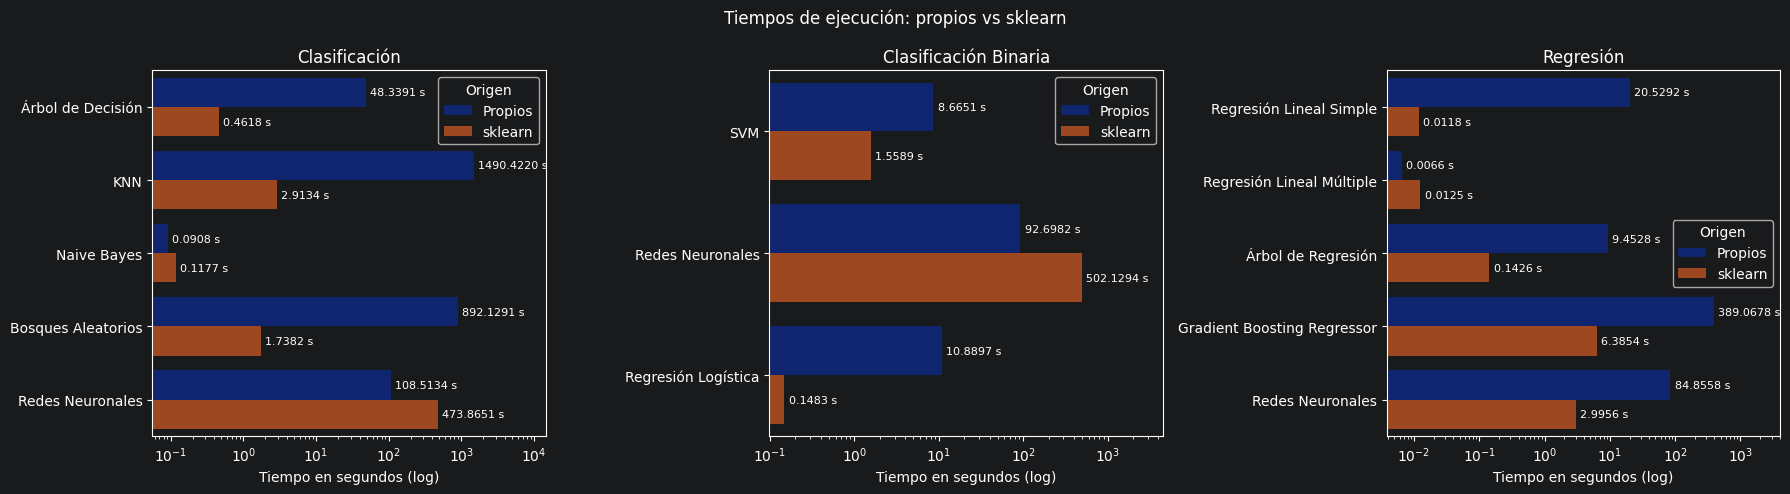

In [ ]:
df_tiempos_class = pd.DataFrame(
    {"Modelo": list(tiempos_class.keys()),
        "Tiempo_seg": list(tiempos_class.values()),
        "Tipo": "Clasificación",}) #con el list solo te convierto los valores que teniamos guardados como tipo diccionario
        # en una lista para que pandas los pueda acomodar

df_tiempos_bin = pd.DataFrame(
    {"Modelo": list(tiempos_bin.keys()),
        "Tiempo_seg": list(tiempos_bin.values()),
        "Tipo": "Clasificación Binaria",})

df_tiempos_reg = pd.DataFrame(
    {"Modelo": list(tiempos_regresion.keys()),
      "Tiempo_seg": list(tiempos_regresion.values()),
     "Tipo": "Regresión", })

df_tiempos_class_sk = pd.DataFrame(
    {"Modelo": list(tiempos_class_sklearn.keys()),
        "Tiempo_seg": list(tiempos_class_sklearn.values()),
        "Tipo": "Clasificación (sklearn)",})

df_tiempos_bin_sk = pd.DataFrame(
    {"Modelo": list(tiempos_bin_sklearn.keys()),
        "Tiempo_seg": list(tiempos_bin_sklearn.values()),
        "Tipo": "Clasificación Binaria (sklearn)",})

df_tiempos_reg_sk = pd.DataFrame(
    {"Modelo": list(tiempos_regresion_sklearn.keys()),
      "Tiempo_seg": list(tiempos_regresion_sklearn.values()),
     "Tipo": "Regresión (sklearn)", })

df_tiempos = pd.concat([df_tiempos_class, df_tiempos_class_sk, df_tiempos_bin, df_tiempos_bin_sk, df_tiempos_reg, df_tiempos_reg_sk])


df_tiempos["Origen"] = np.where(df_tiempos["Tipo"].str.contains("sklearn"), "sklearn", "Propios")
df_tiempos["Tarea"] = df_tiempos["Tipo"].str.replace(" (sklearn)", "", regex=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, tarea in zip(axes, ["Clasificación", "Clasificación Binaria", "Regresión"]):
    sns.barplot(
        data=df_tiempos[df_tiempos["Tarea"] == tarea],
        x="Tiempo_seg",
        y="Modelo",
        hue="Origen",
        palette="dark",
        ax=ax)
    ax.set_xscale("log")
    ax.set_xlim(right=ax.get_xlim()[1] * 6)  # espacio para que quepan las etiquetas
    for c in ax.containers:
        ax.bar_label(c, fmt="%.4f s", padding=3, fontsize=8)  # tiempo al lado de la barra
    ax.set_title(tarea)
    ax.set_xlabel("Tiempo en segundos (log)")
    ax.set_ylabel("")

fig.suptitle("Tiempos de ejecución: propios vs sklearn")
plt.tight_layout()
plt.show()

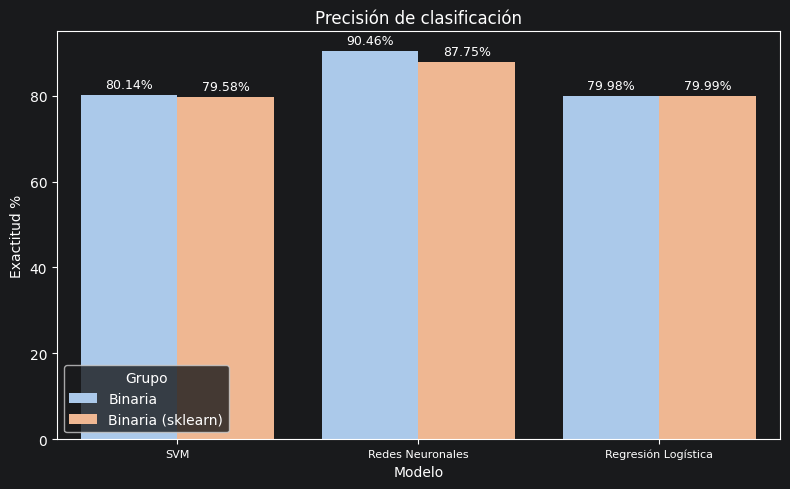

In [ ]:

df_bin_acc = pd.DataFrame(
    {"Modelo": list(resultados_bin.keys()),
        "Exactitud": [v * 100 for v in resultados_bin.values()],
        "Grupo": "Binaria"})

df_bin_acc_sk = pd.DataFrame(
    {"Modelo": list(resultados_bin_sklearn.keys()),
        "Exactitud": [v * 100 for v in resultados_bin_sklearn.values()],
        "Grupo": "Binaria (sklearn)"})

df_acc_total = pd.concat([df_bin_acc, df_bin_acc_sk])

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_acc_total,
    x="Modelo",
    y="Exactitud",
    hue="Grupo",
    palette="pastel")

plt.title("Precisión de clasificación")
plt.ylabel("Exactitud %")
plt.xlabel("Modelo")
plt.xticks(fontsize=8)# este es para que no se superpongan la de redes neuronales y la logistica en el nombre, quitala este comando para que veas que digo

for p in ax.patches: # este es para poner los porcentajes en las barras de exactitud
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f"{h:.2f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontsize=9,)

plt.tight_layout()
plt.show()

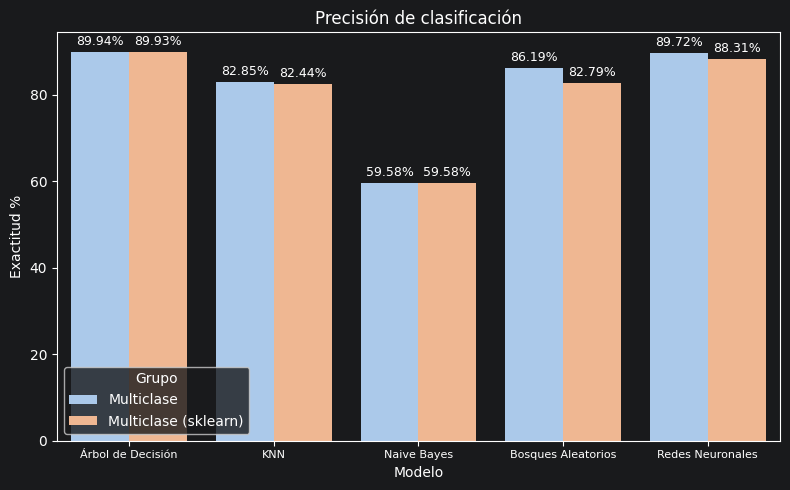

In [ ]:
df_class_acc = pd.DataFrame(
    {"Modelo": list(resultados_class.keys()),
        "Exactitud": [v * 100 for v in resultados_class.values()],
        "Grupo": "Multiclase"})

df_class_acc_sk = pd.DataFrame(
    {"Modelo": list(resultados_class_sklearn.keys()),
        "Exactitud": [v * 100 for v in resultados_class_sklearn.values()],
        "Grupo": "Multiclase (sklearn)"})

df_acc_total = pd.concat([df_class_acc, df_class_acc_sk])

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_acc_total,
    x="Modelo",
    y="Exactitud",
    hue="Grupo",
    palette="pastel")

plt.title("Precisión de clasificación")
plt.ylabel("Exactitud %")
plt.xlabel("Modelo")
plt.xticks(
    fontsize=8)  # este es para que no se superpongan la de redes neuronales y la logistica en el nombre, quitala este comando para que veas que digo

for p in ax.patches:  # este es para poner los porcentajes en las barras de exactitud
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f"{h:.2f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontsize=9, )

plt.tight_layout()
plt.show()


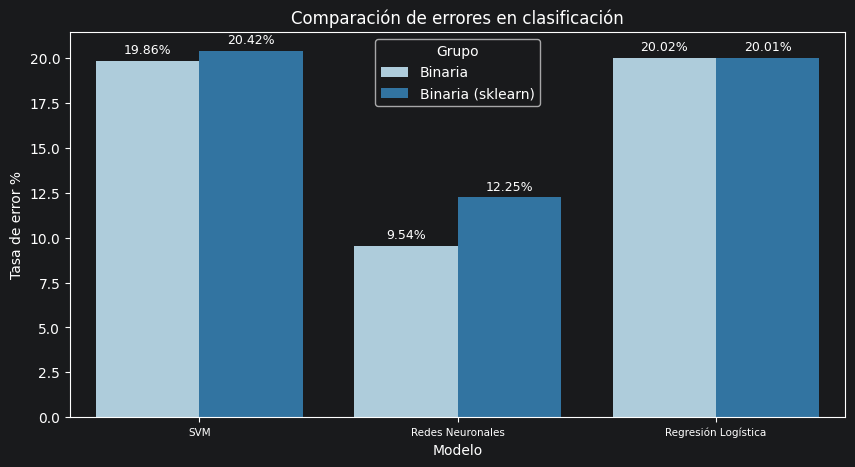

In [ ]:

df_bin_err = pd.DataFrame(
    {"Modelo": list(resultados_bin.keys()),
      "Error_Porcentaje": [(1 - v) * 100 for v in resultados_bin.values()],
      "Grupo": "Binaria"})

df_bin_err_sk = pd.DataFrame(
    {"Modelo": list(resultados_bin_sklearn.keys()),
      "Error_Porcentaje": [(1 - v) * 100 for v in resultados_bin_sklearn.values()],
      "Grupo": "Binaria (sklearn)"})

df_err_total = pd.concat([df_bin_err, df_bin_err_sk])


plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_err_total,
    x="Modelo",
    y="Error_Porcentaje",
    hue="Grupo",
    palette="Paired",#estas las estoy cambiando solo pq me gusta como cambia el color jaja, al final nos decidimos por una paleta
)
plt.title("Comparación de errores en clasificación")
plt.ylabel("Tasa de error %")
plt.xlabel("Modelo")
plt.xticks(fontsize=7.5)# tamaño

for p in ax.patches: #lo mismo que explique en las anteriores
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f"{h:.2f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontsize=9)
plt.show()

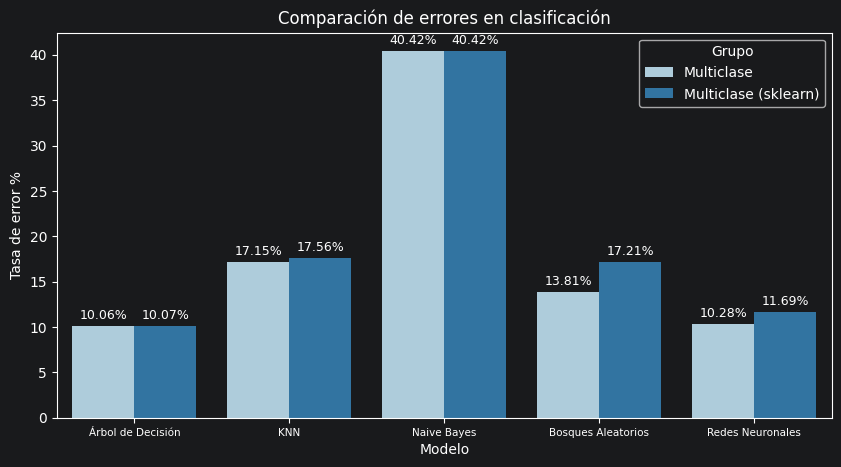

In [ ]:
df_class_err = pd.DataFrame(
    {"Modelo": list(resultados_class.keys()),
      "Error_Porcentaje": [(1 - v) * 100 for v in resultados_class.values()],
      "Grupo": "Multiclase"})

df_class_err_sk = pd.DataFrame(
    {"Modelo": list(resultados_class_sklearn.keys()),
      "Error_Porcentaje": [(1 - v) * 100 for v in resultados_class_sklearn.values()],
      "Grupo": "Multiclase (sklearn)"})

df_err_total = pd.concat([df_class_err, df_class_err_sk])

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_err_total,
    x="Modelo",
    y="Error_Porcentaje",
    hue="Grupo",
    palette="Paired"
)
plt.title("Comparación de errores en clasificación")
plt.ylabel("Tasa de error %")
plt.xlabel("Modelo")
plt.xticks(fontsize=7.5)# tamaño

for p in ax.patches: #lo mismo que explique en las anteriores
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f"{h:.2f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontsize=9)
plt.show()

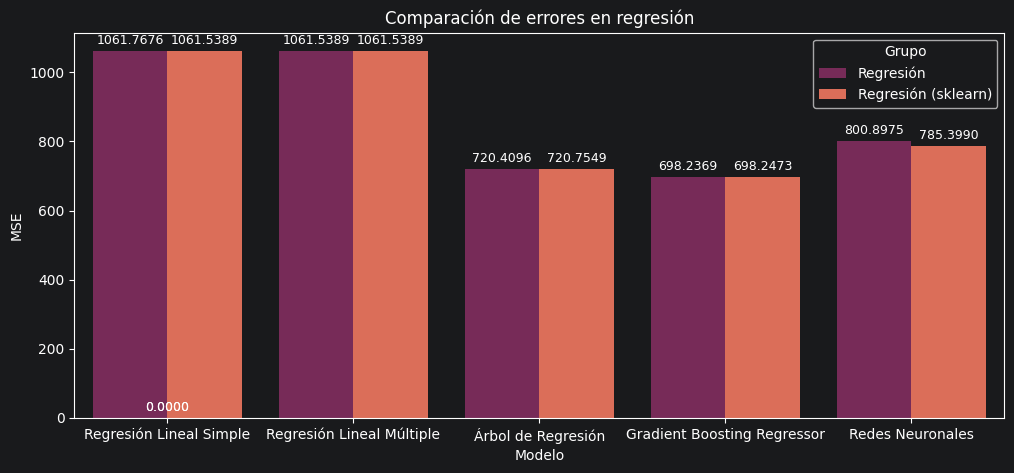

In [ ]:
df_reg_mse = pd.DataFrame(
    {"Modelo": list(resultados_mse.keys()),
      "MSE": list(resultados_mse.values()),
      "Grupo": "Regresión"})

df_reg_mse_sk = pd.DataFrame(
    {"Modelo": list(resultados_mse_sklearn.keys()),
      "MSE": list(resultados_mse_sklearn.values()),
      "Grupo": "Regresión (sklearn)"})

df_reg_mse = pd.concat([df_reg_mse, df_reg_mse_sk])

plt.figure(figsize=(12, 5))
ax = sns.barplot(
    data=df_reg_mse,
    x="Modelo",
    y="MSE",
    hue="Grupo",
    palette="rocket")

plt.title("Comparación de errores en regresión")
plt.ylabel("MSE")
plt.xlabel("Modelo")
plt.xticks(fontsize=10)

for p in ax.patches: #lo mismo que te dije por mensaje
    h = p.get_height()
    ax.annotate(
        f"{h:.4f}",
        (p.get_x() + p.get_width() / 2.0, h),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
        fontsize=9)

plt.show()
#toti en esta los errores se ven asi de pequenos pq estaba viendo nuestra metrica de severity y pues llegan valores muy pequenos, ademas use el MSE, y esto hace los errores mucho mas pequenos por eso se v easi
#tal vez tengamos que cambiar eso.

graficas  etc.

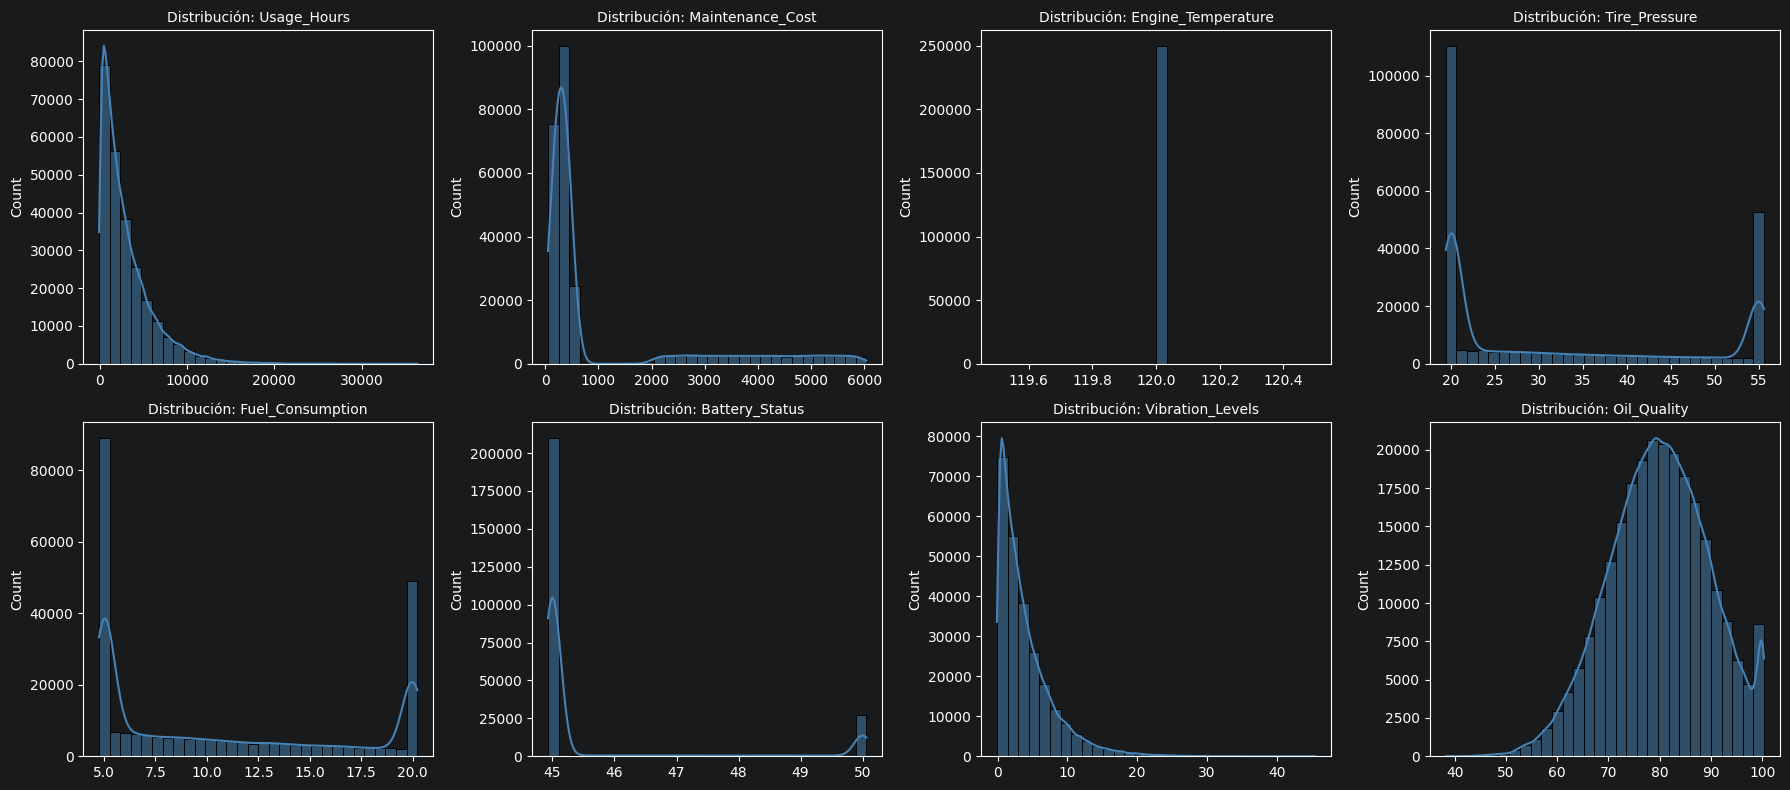

In [ ]:
vars_numericas = [
    'Usage_Hours', 'Maintenance_Cost', 'Engine_Temperature', 'Tire_Pressure',
    'Fuel_Consumption', 'Battery_Status', 'Vibration_Levels', 'Oil_Quality'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(vars_numericas):
    sns.histplot(data=df, x=col, kde=True, bins=30, color='steelblue', ax=axes[i])
    axes[i].set_title(f'Distribución: {col}', fontsize=10)
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

C:\Users\Toti\AppData\Local\Temp\ipykernel_12576\1538798786.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Maintenance_Required', order=[0, 1], palette='Set2', ax=axes[0])
C:\Users\Toti\AppData\Local\Temp\ipykernel_12576\1538798786.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No (0)', 'Sí (1)'])
C:\Users\Toti\AppData\Local\Temp\ipykernel_12576\1538798786.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Maintenance_Level', order=[1, 2, 3], palette='viridis', ax=axes[1])
C:\Users\Toti\AppData\Local\Temp\ipykernel_12576\1538798786.py:12: Use

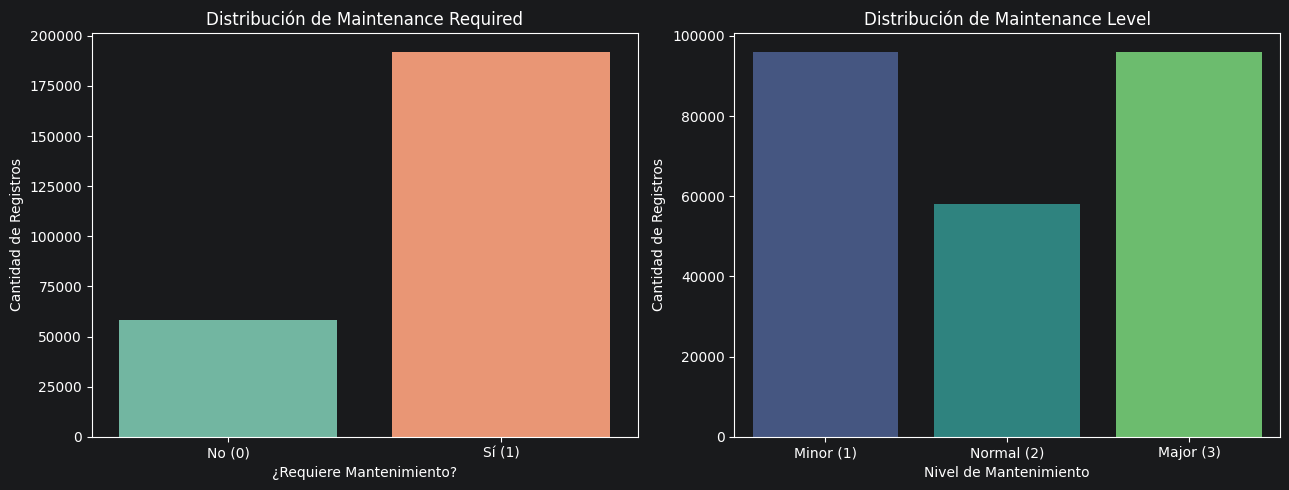

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x='Maintenance_Required', order=[0, 1], palette='Set2', ax=axes[0])
axes[0].set_title('Distribución de Maintenance Required', fontsize=12)
axes[0].set_xticklabels(['No (0)', 'Sí (1)'])
axes[0].set_xlabel('¿Requiere Mantenimiento?')
axes[0].set_ylabel('Cantidad de Registros')


sns.countplot(data=df, x='Maintenance_Level', order=[1, 2, 3], palette='viridis', ax=axes[1])
axes[1].set_title('Distribución de Maintenance Level', fontsize=12)
axes[1].set_xticklabels(['Minor (1)', 'Normal (2)', 'Major (3)'])
axes[1].set_xlabel('Nivel de Mantenimiento')
axes[1].set_ylabel('Cantidad de Registros')

plt.tight_layout()
plt.show()

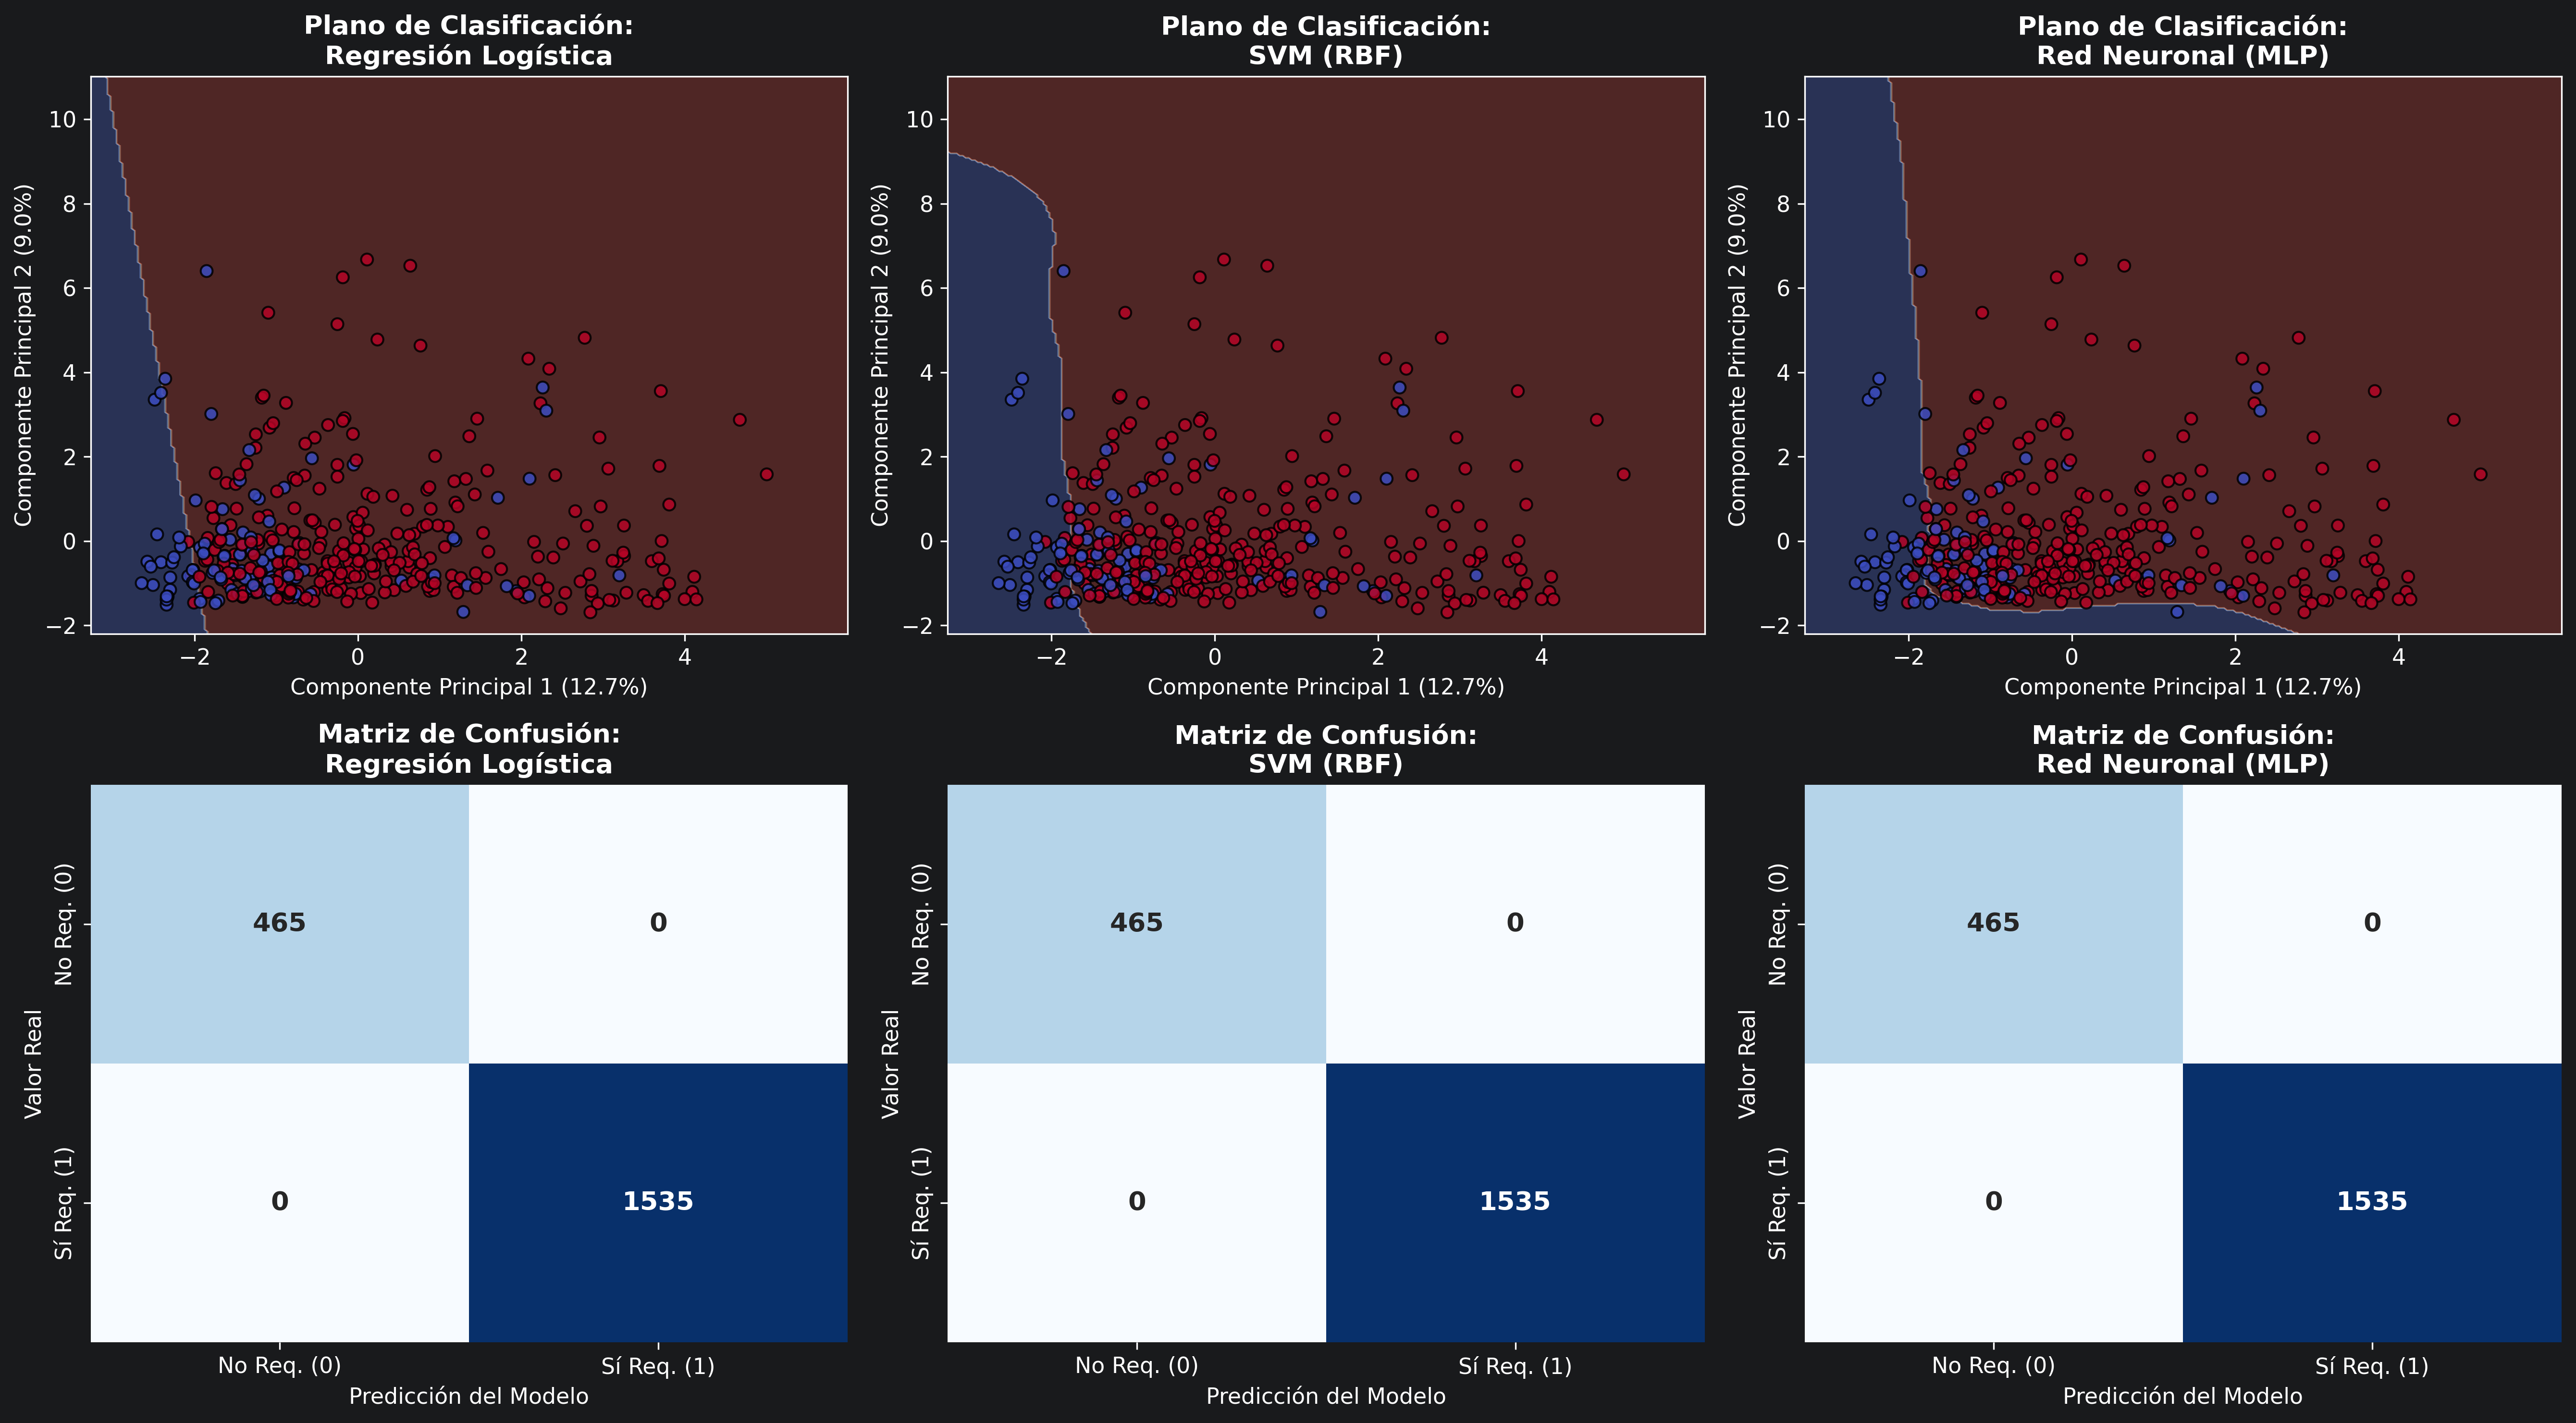

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

y_clf = df['Maintenance_Required'].to_numpy()
X_clf = df.drop(
    columns=['Maintenance_Required', 'Maintenance_Level'],
    errors='ignore'
).select_dtypes(include=[np.number]).to_numpy()

if len(X_clf) > 10000:
    X_clf, _, y_clf, _ = train_test_split(
        X_clf, y_clf, train_size=10000, stratify=y_clf, random_state=42
    )

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, stratify=y_clf, random_state=42
)

scaler_clf = StandardScaler()
X_train_sc = scaler_clf.fit_transform(X_train_clf)
X_test_sc = scaler_clf.transform(X_test_clf)

# 2. Modelos completos (todas las variables)
modelos_clf = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Red Neuronal (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

for modelo in modelos_clf.values():
    modelo.fit(X_train_sc, y_train_clf)

pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_sc)
X_test_2d = pca.transform(X_test_sc)
var_exp = pca.explained_variance_ratio_ * 100

modelos_2d = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Red Neuronal (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

x_min, x_max = X_test_2d[:, 0].min() - 0.5, X_test_2d[:, 0].max() + 0.5
y_min, y_max = X_test_2d[:, 1].min() - 0.5, X_test_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

rng = np.random.default_rng(42)
idx_vis = rng.choice(len(X_test_2d), size=min(400, len(X_test_2d)), replace=False)

# 4. Gráfica 2x3 para el póster
fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=300)

for i, (nombre, modelo_2d) in enumerate(modelos_2d.items()):
    modelo_2d.fit(X_train_2d, y_train_clf)
    Z = modelo_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    axes[0, i].contourf(xx, yy, Z, alpha=0.30, cmap='coolwarm')
    axes[0, i].scatter(
        X_test_2d[idx_vis, 0], X_test_2d[idx_vis, 1],
        c=y_test_clf[idx_vis], cmap='coolwarm', edgecolors='k', s=35, alpha=0.85
    )
    axes[0, i].set_title(f'Plano de Clasificación:\n{nombre}')
    axes[0, i].set_xlabel(f'Componente Principal 1 ({var_exp[0]:.1f}%)')
    axes[0, i].set_ylabel(f'Componente Principal 2 ({var_exp[1]:.1f}%)')

    y_pred_full = modelos_clf[nombre].predict(X_test_sc)
    cm = confusion_matrix(y_test_clf, y_pred_full)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['No Req. (0)', 'Sí Req. (1)'],
        yticklabels=['No Req. (0)', 'Sí Req. (1)'],
        ax=axes[1, i], annot_kws={'size': 13, 'weight': 'bold'}
    )
    axes[1, i].set_title(f'Matriz de Confusión:\n{nombre}')
    axes[1, i].set_xlabel('Predicción del Modelo')
    axes[1, i].set_ylabel('Valor Real')

plt.tight_layout()
plt.savefig('2_planos_y_clasificacion_poster.png', dpi=300, bbox_inches='tight')
plt.show()

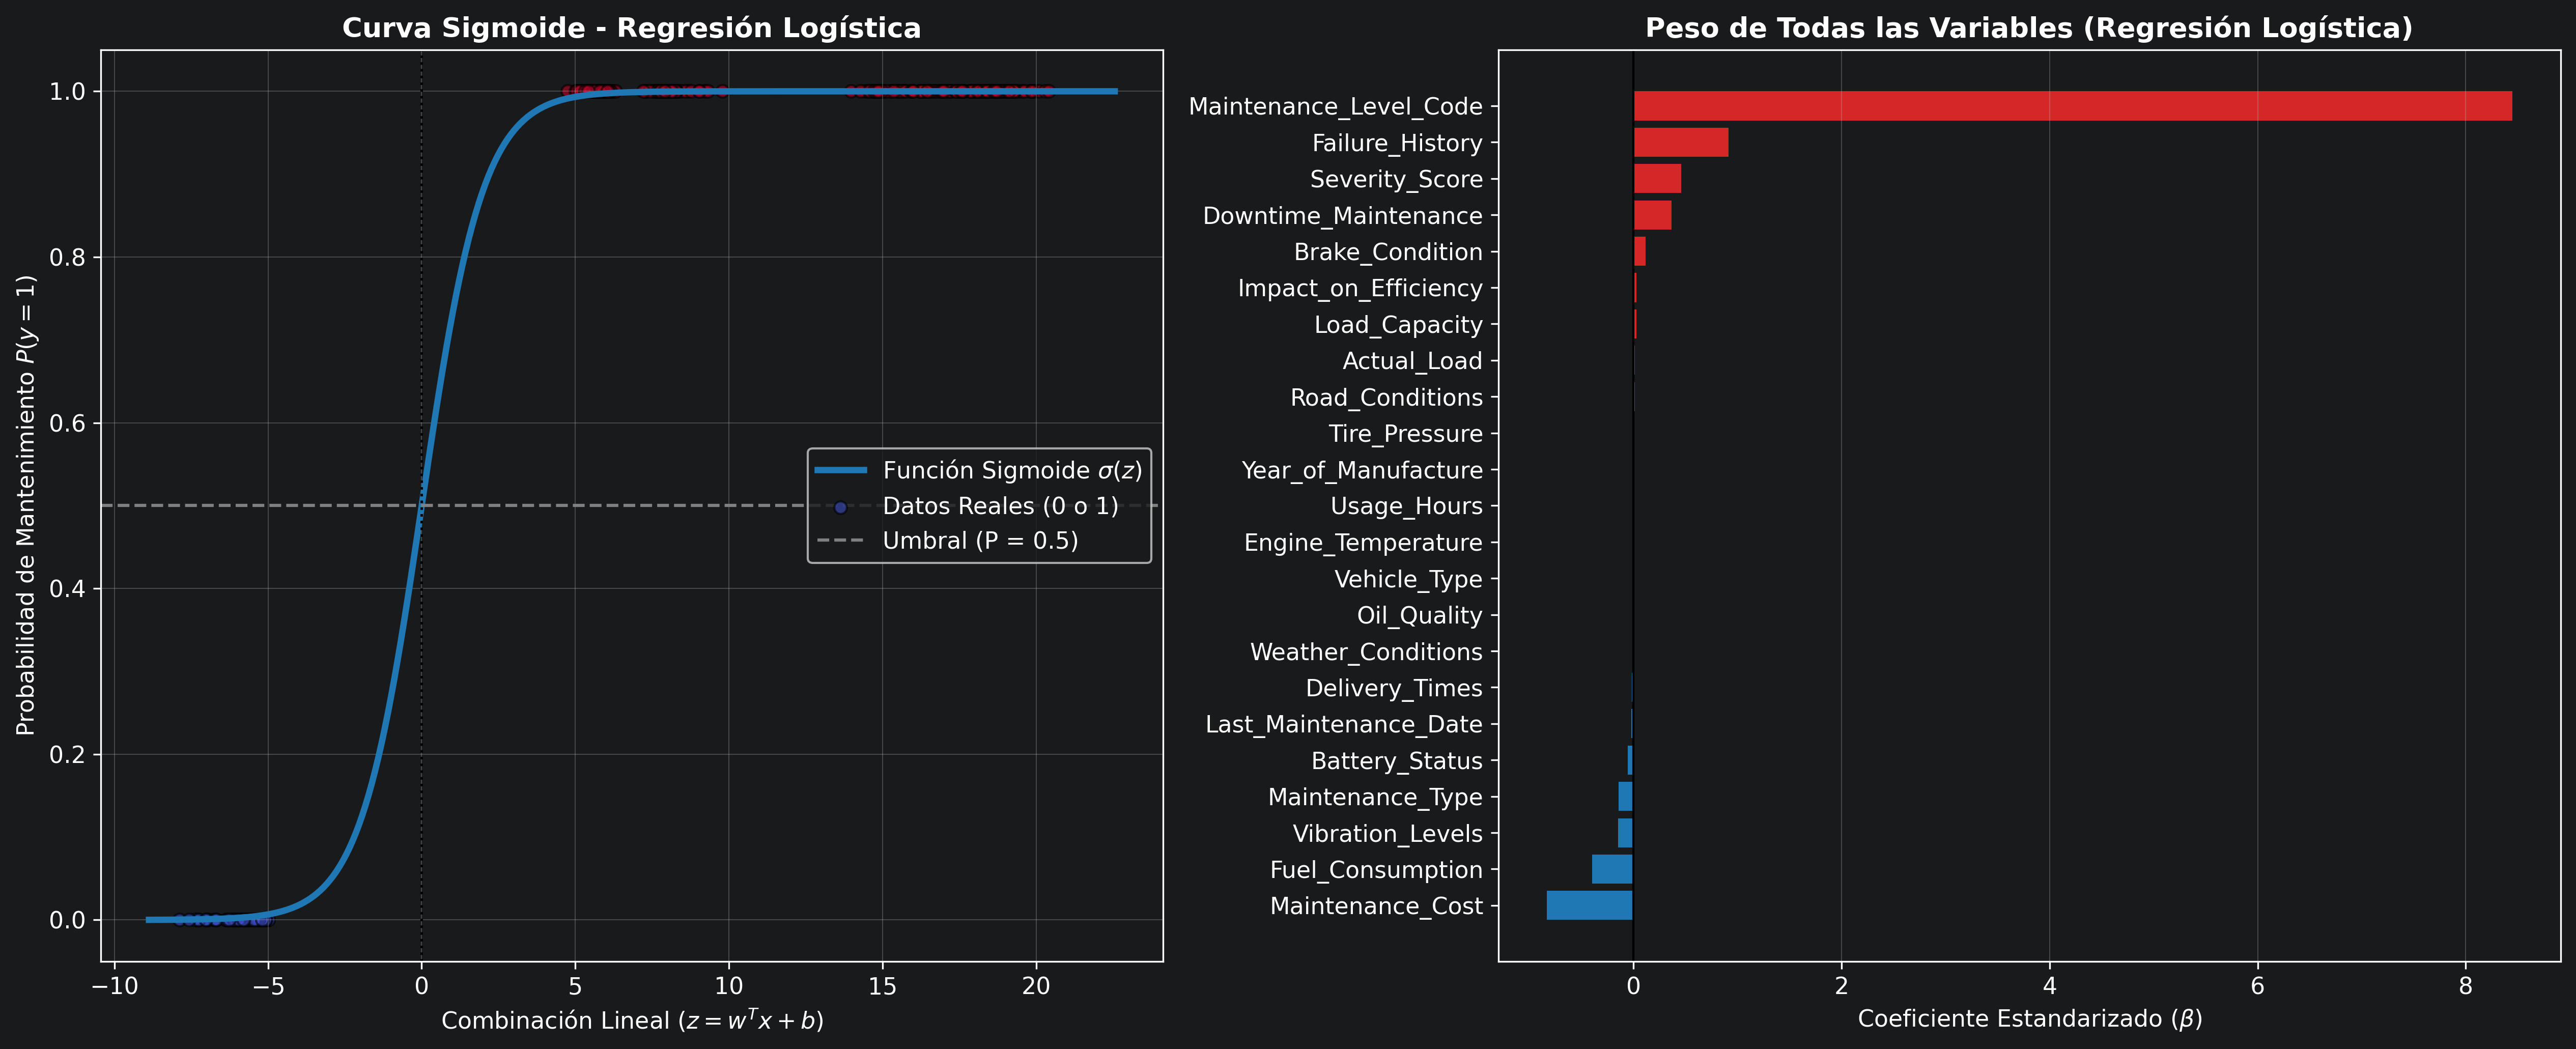

In [ ]:
log_reg = modelos_clf['Regresión Logística']

nombres_clf = df.drop(
    columns=['Maintenance_Required', 'Maintenance_Level'],
    errors='ignore'
).select_dtypes(include=[np.number]).columns

fig, axes = plt.subplots(1, 2, figsize=(17, 7), dpi=300)

# Curva Sigmoide
z_test = log_reg.decision_function(X_test_sc)
z_grid = np.linspace(z_test.min() - 1, z_test.max() + 1, 300)
sigmoide = 1 / (1 + np.exp(-z_grid))

axes[0].plot(z_grid, sigmoide, color='#1f77b4', lw=3, label='Función Sigmoide $\\sigma(z)$')
axes[0].scatter(
    z_test[idx_vis], y_test_clf[idx_vis],
    c=y_test_clf[idx_vis], cmap='coolwarm', edgecolors='k', alpha=0.6, s=35,
    label='Datos Reales (0 o 1)'
)
axes[0].axhline(0.5, color='gray', linestyle='--', lw=1.5, label='Umbral (P = 0.5)')
axes[0].axvline(0.0, color='black', linestyle=':', lw=1.2)
axes[0].set_title('Curva Sigmoide - Regresión Logística')
axes[0].set_xlabel('Combinación Lineal ($z = w^T x + b$)')
axes[0].set_ylabel('Probabilidad de Mantenimiento $P(y=1)$')
axes[0].legend(loc='center right')
axes[0].grid(alpha=0.3)

coef_df = pd.DataFrame({
    'Variable': nombres_clf,
    'Coeficiente': log_reg.coef_[0]
}).sort_values(by='Coeficiente', ascending=True)

colores_barras = ['#d62728' if c > 0 else '#1f77b4' for c in coef_df['Coeficiente']]
axes[1].barh(coef_df['Variable'], coef_df['Coeficiente'], color=colores_barras)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_title('Peso de Todas las Variables (Regresión Logística)')
axes[1].set_xlabel('Coeficiente Estandarizado ($\\beta$)')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('3_graficas_regresion_logistica.png', dpi=300, bbox_inches='tight')
plt.show()

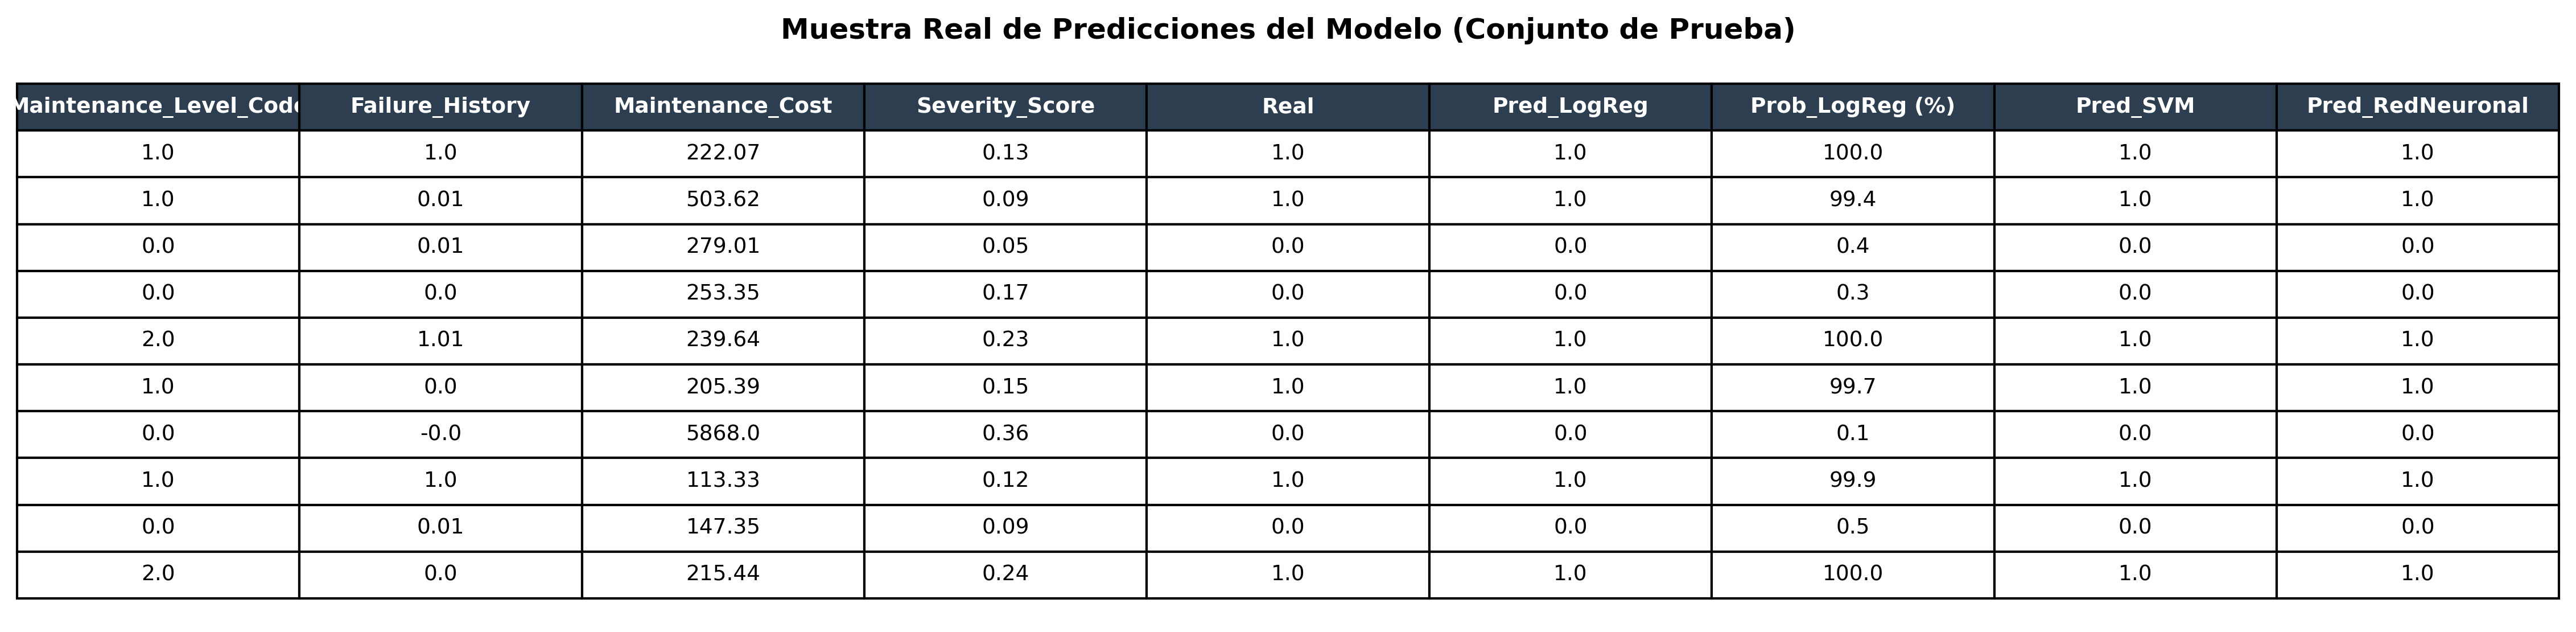

In [ ]:
posiciones_test = pd.Series(y_test_clf).sample(n=10, random_state=42).index.to_numpy()

# Selecciona las 4 variables con mayor peso en la regresión logística para resumir la fila
top_vars = coef_df.reindex(coef_df['Coeficiente'].abs().sort_values(ascending=False).index)['Variable'].head(4).tolist()

df_muestra_real = pd.DataFrame(X_test_clf[posiciones_test], columns=nombres_clf)[top_vars].copy()
df_muestra_real['Real'] = y_test_clf[posiciones_test]
df_muestra_real['Pred_LogReg'] = modelos_clf['Regresión Logística'].predict(X_test_sc[posiciones_test])
df_muestra_real['Prob_LogReg (%)'] = (modelos_clf['Regresión Logística'].predict_proba(X_test_sc[posiciones_test])[:, 1] * 100).round(1)
df_muestra_real['Pred_SVM'] = modelos_clf['SVM (RBF)'].predict(X_test_sc[posiciones_test])
df_muestra_real['Pred_RedNeuronal'] = modelos_clf['Red Neuronal (MLP)'].predict(X_test_sc[posiciones_test])

with plt.style.context('default'):  # fondo blanco y texto negro, solo para esta figura
    fig, ax = plt.subplots(figsize=(15, 3.8), dpi=300)
    ax.axis('off')
    tabla = ax.table(
        cellText=df_muestra_real.round(2).values,
        colLabels=df_muestra_real.columns,
        cellLoc='center',
        loc='center'
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.scale(1.1, 1.5)

    for (row, col), cell in tabla.get_celld().items():
        if row == 0:
            cell.set_facecolor('#2c3e50')
            cell.set_text_props(color='white', weight='bold')

    plt.title('Muestra Real de Predicciones del Modelo (Conjunto de Prueba)', weight='bold', pad=12)
    plt.tight_layout()
    plt.savefig('4_muestra_real_condensada_poster.png', dpi=300, bbox_inches='tight')
    plt.show()

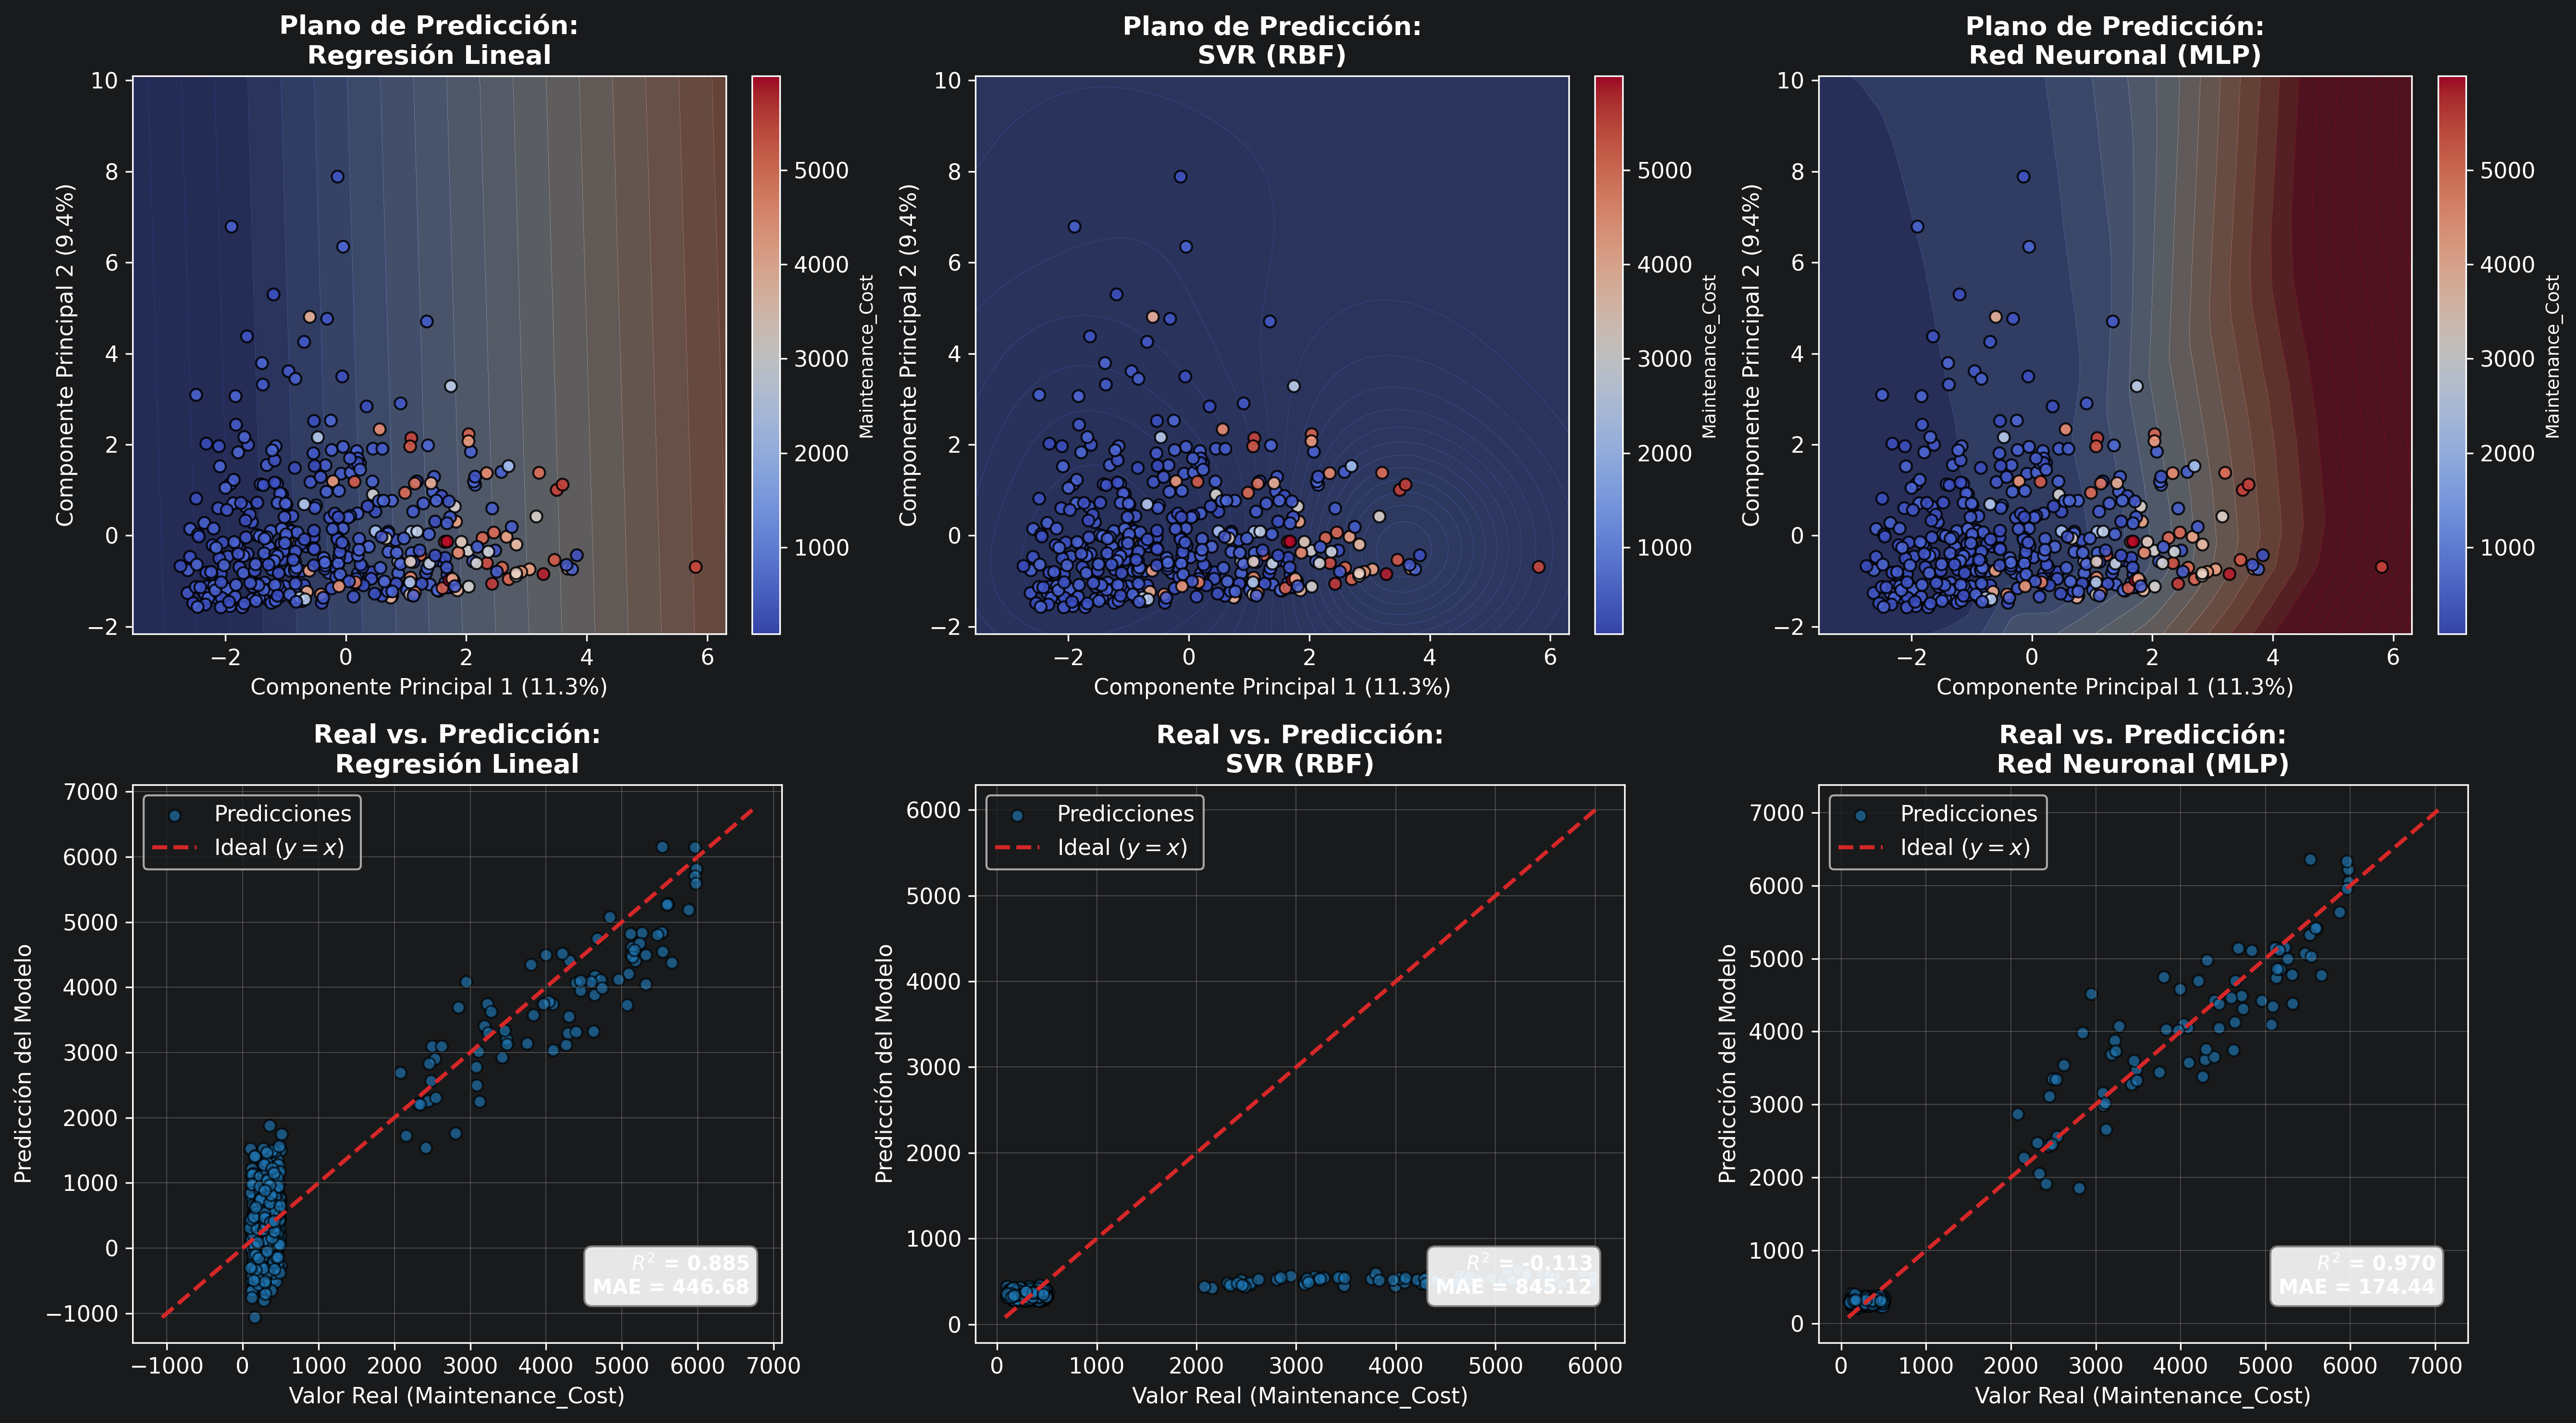

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# 1. Variable numérica a predecir (puedes cambiarla por 'Downtime_Maintenance', etc.)
target_pred = 'Maintenance_Cost'

y_reg = df[target_pred].copy()
X_reg = df.drop(
    columns=[target_pred, 'Maintenance_Required', 'Maintenance_Level'],
    errors='ignore'
).select_dtypes(include=[np.number]).copy()

if len(X_reg) > 10000:
    X_mod, _, y_mod, _ = train_test_split(X_reg, y_reg, train_size=10000, random_state=42)
else:
    X_mod, y_mod = X_reg, y_reg

X_train, X_test, y_train, y_test = train_test_split(
    X_mod, y_mod, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelos_pred = {
    'Regresión Lineal': LinearRegression(),
    'SVR (RBF)': SVR(kernel='rbf'),
    'Red Neuronal (MLP)': MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

for nombre, modelo in modelos_pred.items():
    modelo.fit(X_train_scaled, y_train)


pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)
var_exp = pca.explained_variance_ratio_ * 100

modelos_pred_2d = {
    'Regresión Lineal': LinearRegression(),
    'SVR (RBF)': SVR(kernel='rbf'),
    'Red Neuronal (MLP)': MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

x_min, x_max = X_test_2d[:, 0].min() - 0.5, X_test_2d[:, 0].max() + 0.5
y_min, y_max = X_test_2d[:, 1].min() - 0.5, X_test_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

rng = np.random.default_rng(42)
idx_vis = rng.choice(len(X_test_2d), size=min(400, len(X_test_2d)), replace=False)

# 4. Generación de la figura 2x3 estilo póster
fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=300)

vmin, vmax = y_test.min(), y_test.max()

for i, (nombre, modelo_2d) in enumerate(modelos_pred_2d.items()):
    # --- Fila 1: Plano de Predicción 2D ---
    modelo_2d.fit(X_train_2d, y_train)
    Z = modelo_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    contorno = axes[0, i].contourf(xx, yy, Z, levels=20, alpha=0.35, cmap='coolwarm', vmin=vmin, vmax=vmax)
    sc = axes[0, i].scatter(
        X_test_2d[idx_vis, 0], X_test_2d[idx_vis, 1],
        c=y_test.iloc[idx_vis], cmap='coolwarm', vmin=vmin, vmax=vmax,
        edgecolors='k', s=35, alpha=0.85
    )
    axes[0, i].set_title(f'Plano de Predicción:\n{nombre}')
    axes[0, i].set_xlabel(f'Componente Principal 1 ({var_exp[0]:.1f}%)')
    axes[0, i].set_ylabel(f'Componente Principal 2 ({var_exp[1]:.1f}%)')
    cbar = plt.colorbar(sc, ax=axes[0, i], fraction=0.046, pad=0.04)
    cbar.set_label(target_pred, fontsize=9)

    #Real vs. Predicción (con todas las variables) ---
    y_pred_full = modelos_pred[nombre].predict(X_test_scaled)
    r2 = r2_score(y_test, y_pred_full)
    mae = mean_absolute_error(y_test, y_pred_full)

    axes[1, i].scatter(
        y_test.iloc[idx_vis], y_pred_full[idx_vis],
        color='#1f77b4', edgecolors='k', alpha=0.65, s=35, label='Predicciones'
    )
    # Línea diagonal de predicción perfecta (y = x)
    lims = [min(vmin, y_pred_full.min()), max(vmax, y_pred_full.max())]
    axes[1, i].plot(lims, lims, color='#d62728', linestyle='--', lw=2, label='Ideal ($y = x$)')

    axes[1, i].set_title(f'Real vs. Predicción:\n{nombre}')
    axes[1, i].set_xlabel(f'Valor Real ({target_pred})')
    axes[1, i].set_ylabel('Predicción del Modelo')
    axes[1, i].legend(loc='upper left', frameon=True)
    axes[1, i].grid(alpha=0.3)

    # Cuadro con métricas R2 y MAE
    axes[1, i].text(
        0.95, 0.08, f'$R^2$ = {r2:.3f}\nMAE = {mae:.2f}',
        transform=axes[1, i].transAxes, ha='right', va='bottom',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.9),
        fontsize=10, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('5_planos_y_prediccion_poster.png', dpi=300, bbox_inches='tight')
plt.show()

Comparando escalabilidad con k=5 vecinos...

N =    500 | KNN Propio (utilities):  0.0035 s | Scikit-Learn:  0.0029 s | Ratio:    1.2x
N =   1000 | KNN Propio (utilities):  0.0063 s | Scikit-Learn:  0.0045 s | Ratio:    1.4x
N =   2500 | KNN Propio (utilities):  0.0364 s | Scikit-Learn:  0.0073 s | Ratio:    5.0x
N =   5000 | KNN Propio (utilities):  0.1465 s | Scikit-Learn:  0.0037 s | Ratio:   39.1x
N =  10000 | KNN Propio (utilities):  2.4417 s | Scikit-Learn:  0.0074 s | Ratio:  330.6x
N =  15000 | KNN Propio (utilities):  5.2245 s | Scikit-Learn:  0.0157 s | Ratio:  332.1x
N =  20000 | KNN Propio (utilities):  8.8166 s | Scikit-Learn:  0.0524 s | Ratio:  168.3x
N =  25000 | KNN Propio (utilities): 13.6806 s | Scikit-Learn:  0.0423 s | Ratio:  323.0x


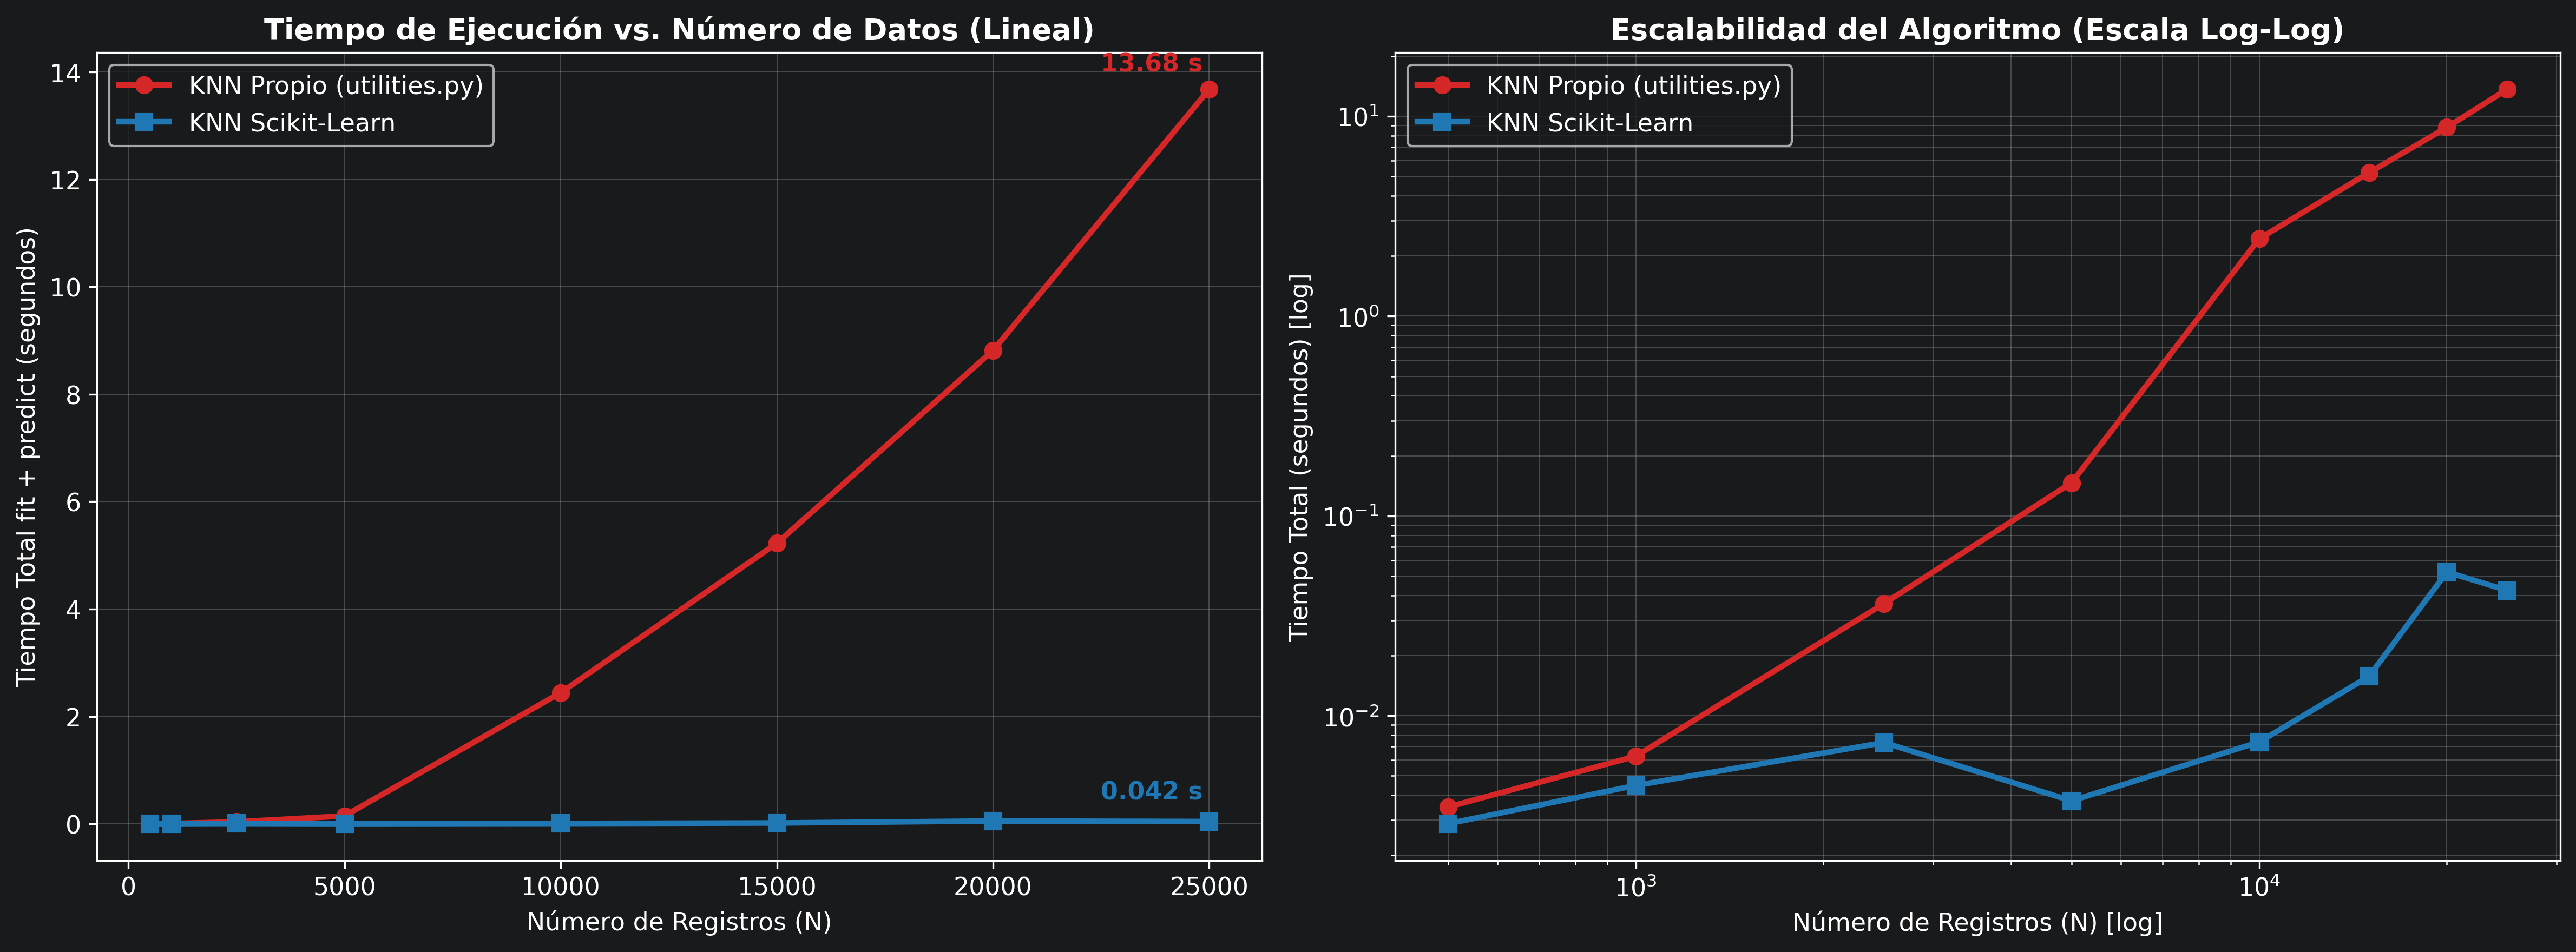

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier as KNNSklearn

from utilities import KNNClassifier as KNNPropio

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

y_full = df['Maintenance_Required'].to_numpy()
X_full = df.drop(
    columns=['Maintenance_Required', 'Maintenance_Level', 'Maintenance_Level_Code', 'Maintenance_Cost'],
    errors='ignore'
).select_dtypes(include=[np.number]).to_numpy()


max_n = min(len(X_full), 25000)
tamanos = [n for n in [500, 1000, 2500, 5000, 10000, 15000, 20000, 25000] if n <= max_n]

k_vecinos = 5
tiempos_propio = []
tiempos_sklearn = []

print(f"Comparando escalabilidad con k={k_vecinos} vecinos...\n")

for n in tamanos:
    if n < len(X_full):
        X_sub, _, y_sub, _ = train_test_split(
            X_full, y_full, train_size=n, stratify=y_full, random_state=42
        )
    else:
        X_sub, y_sub = X_full, y_full

    X_train, X_test, y_train, y_test = train_test_split(
        X_sub, y_sub, test_size=0.20, stratify=y_sub, random_state=42
    )

    # Estandarización (arreglos NumPy para que KNNPropio itere por filas)
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    # --- Tiempo 1: Tu KNN de utilities.py ---
    modelo_propio = KNNPropio(n_neighbors=k_vecinos)
    t_propio = medir(lambda: (modelo_propio.fit(X_train_sc, y_train), modelo_propio.predict(X_test_sc)))
    tiempos_propio.append(t_propio)

    modelo_sk = KNNSklearn(n_neighbors=k_vecinos)
    t_sk = medir(lambda: (modelo_sk.fit(X_train_sc, y_train), modelo_sk.predict(X_test_sc)))
    tiempos_sklearn.append(t_sk)

    print(f"N = {n:>6} | KNN Propio (utilities): {t_propio:7.4f} s | Scikit-Learn: {t_sk:7.4f} s | Ratio: {t_propio/t_sk:6.1f}x")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

axes[0].plot(
    tamanos, tiempos_propio, marker='o', linewidth=2.5, markersize=7,
    color='#d62728', label='KNN Propio (utilities.py)'
)
axes[0].plot(
    tamanos, tiempos_sklearn, marker='s', linewidth=2.5, markersize=7,
    color='#1f77b4', label='KNN Scikit-Learn'
)
axes[0].set_title('Tiempo de Ejecución vs. Número de Datos (Lineal)')
axes[0].set_xlabel('Número de Registros (N)')
axes[0].set_ylabel('Tiempo Total fit + predict (segundos)')
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(alpha=0.3)

axes[0].annotate(
    f'{tiempos_propio[-1]:.2f} s',
    xy=(tamanos[-1], tiempos_propio[-1]), xytext=(-48, 8),
    textcoords='offset points', fontweight='bold', color='#d62728'
)
axes[0].annotate(
    f'{tiempos_sklearn[-1]:.3f} s',
    xy=(tamanos[-1], tiempos_sklearn[-1]), xytext=(-48, 10),
    textcoords='offset points', fontweight='bold', color='#1f77b4'
)

axes[1].loglog(
    tamanos, tiempos_propio, marker='o', linewidth=2.5, markersize=7,
    color='#d62728', label='KNN Propio (utilities.py)'
)
axes[1].loglog(
    tamanos, tiempos_sklearn, marker='s', linewidth=2.5, markersize=7,
    color='#1f77b4', label='KNN Scikit-Learn'
)
axes[1].set_title('Escalabilidad del Algoritmo (Escala Log-Log)')
axes[1].set_xlabel('Número de Registros (N) [log]')
axes[1].set_ylabel('Tiempo Total (segundos) [log]')
axes[1].legend(loc='upper left', frameon=True)
axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('6_escalabilidad_knn_utilities.png', dpi=300, bbox_inches='tight')
plt.show()

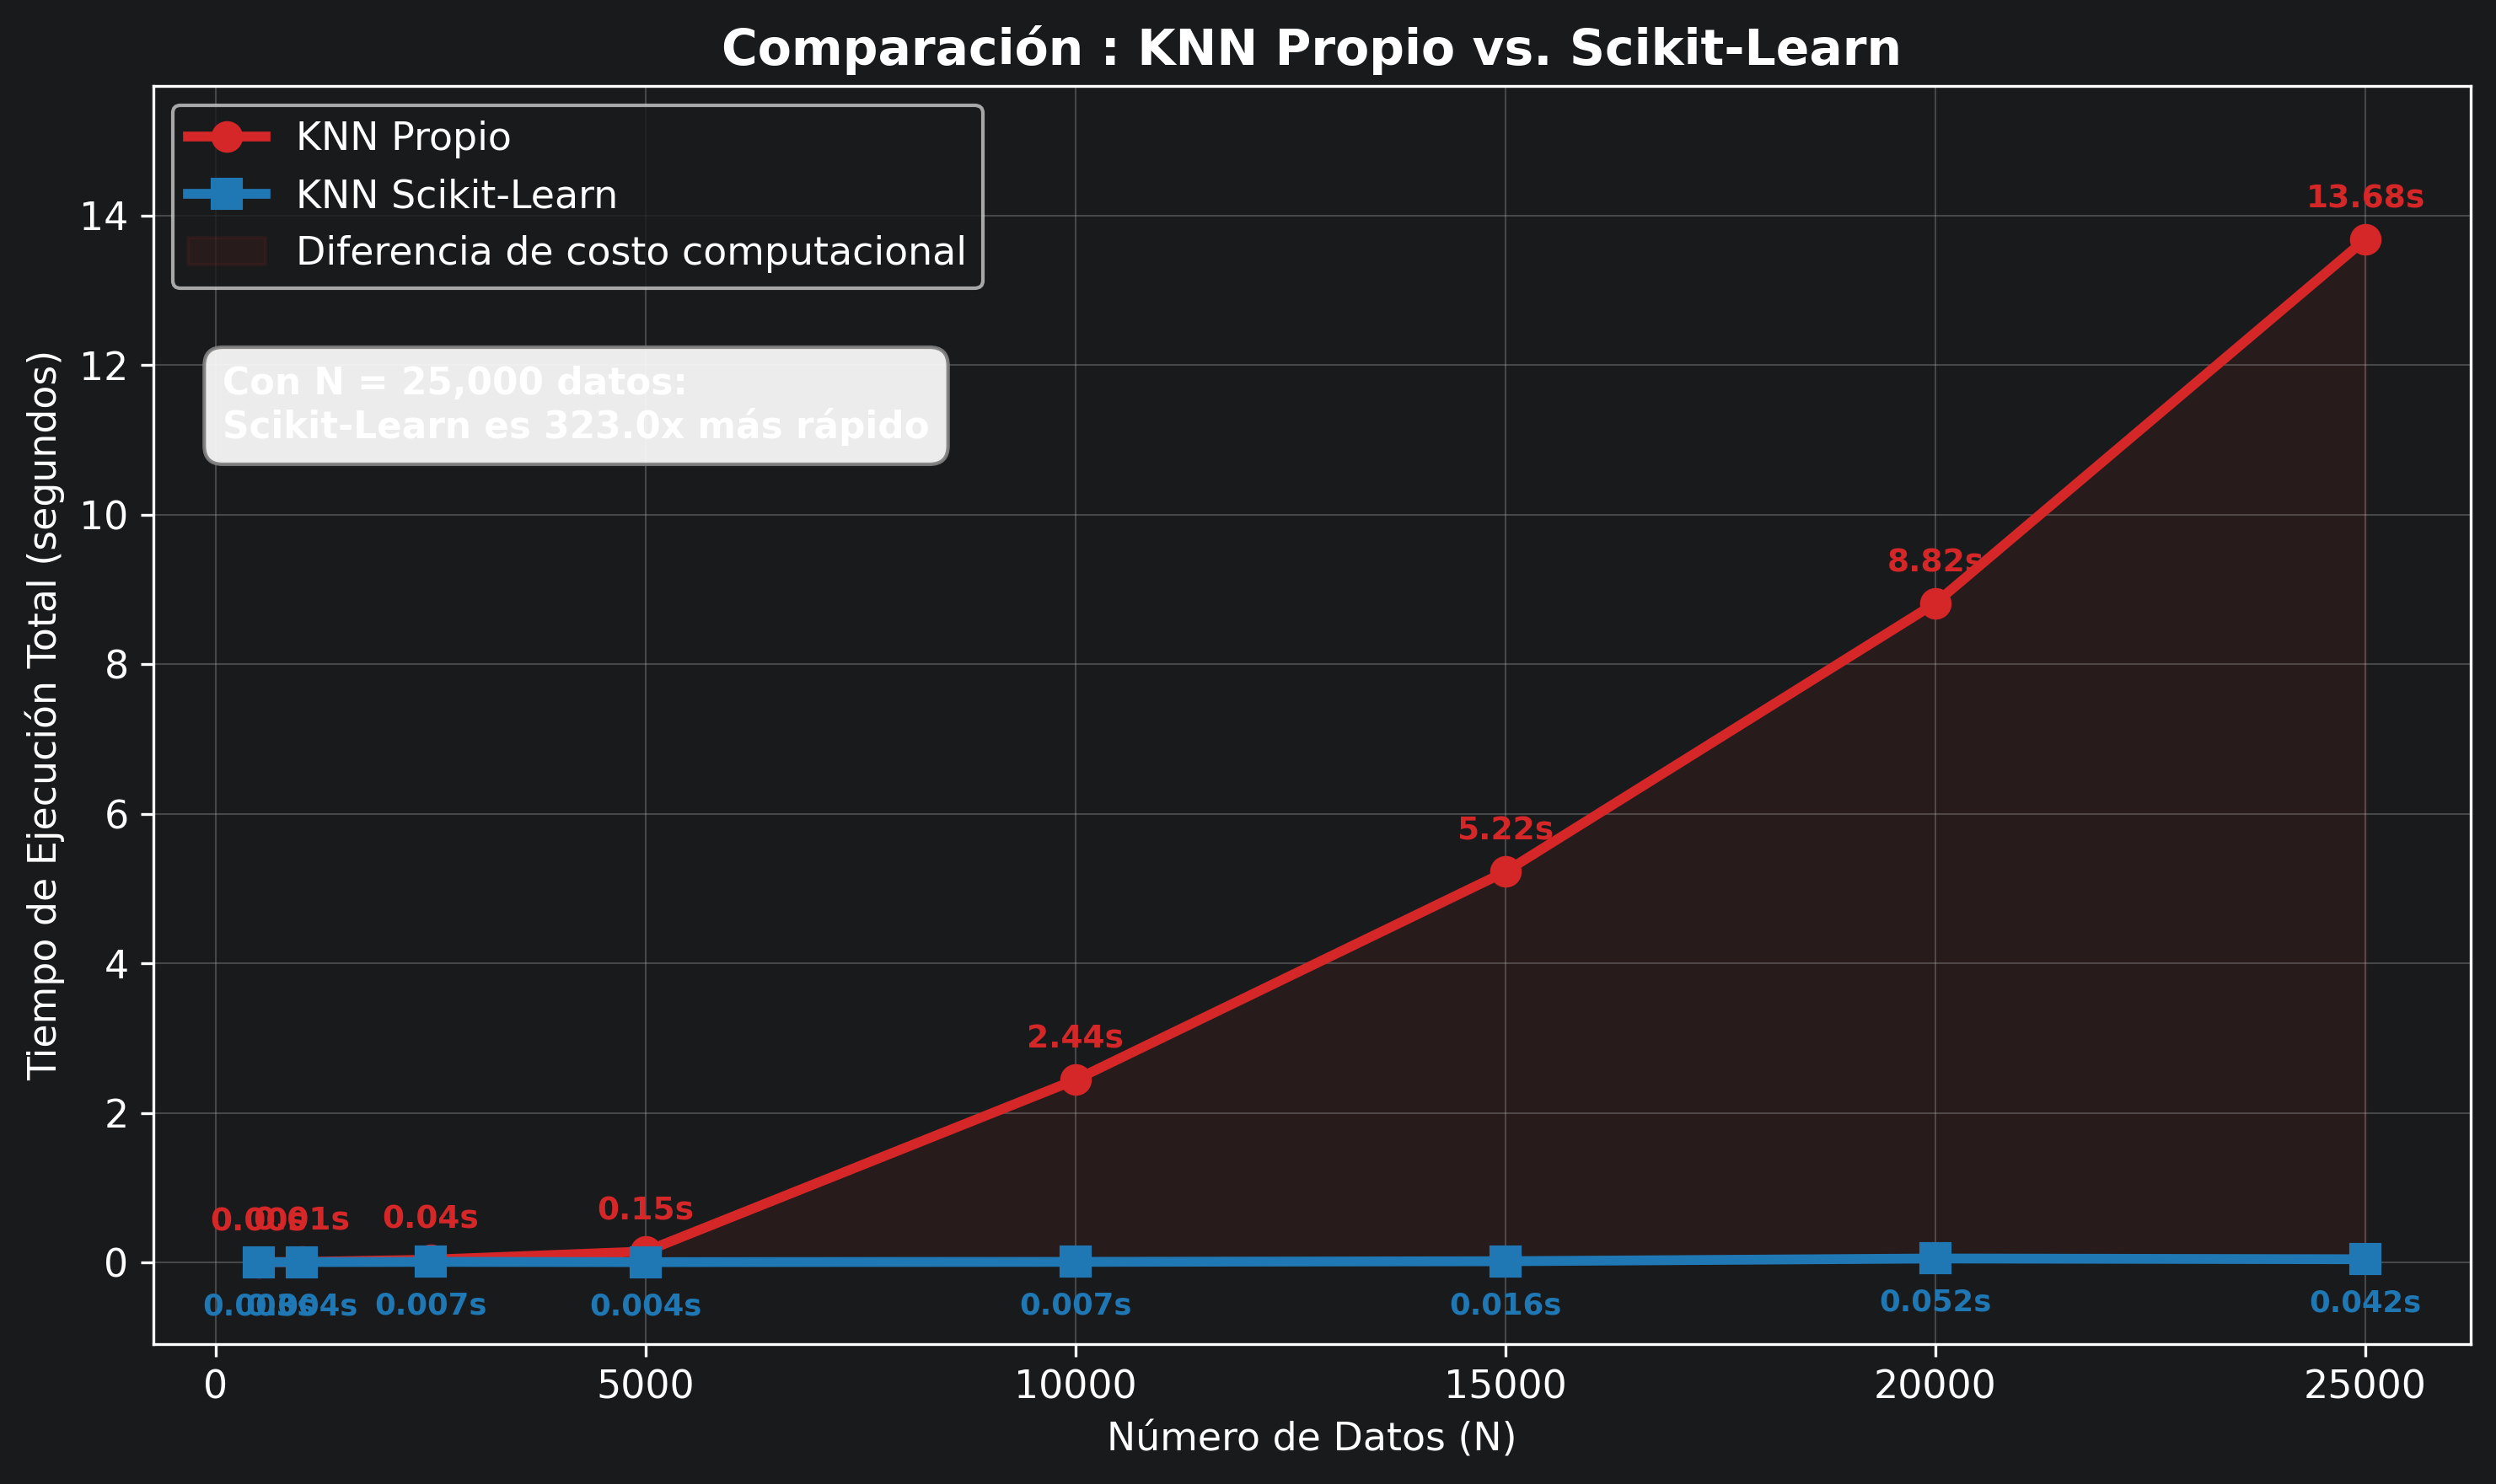

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier as KNNSklearn
from utilities import KNNClassifier as KNNPropio

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Usa tamanos, tiempos_propio y tiempos_sklearn medidos en la celda anterior (no vuelve a medir)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

ax.plot(
    tamanos, tiempos_propio, marker='o', linewidth=2.8, markersize=8,
    color='#d62728', label='KNN Propio', zorder=3
)
ax.plot(
    tamanos, tiempos_sklearn, marker='s', linewidth=2.8, markersize=8,
    color='#1f77b4', label='KNN Scikit-Learn', zorder=4
)

ax.fill_between(
    tamanos, tiempos_sklearn, tiempos_propio,
    color='#d62728', alpha=0.08, label='Diferencia de costo computacional'
)

for x, y_p, y_s in zip(tamanos, tiempos_propio, tiempos_sklearn):
    ax.annotate(
        f'{y_p:.2f}s', (x, y_p), textcoords='offset points',
        xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#d62728'
    )
    ax.annotate(
        f'{y_s:.3f}s', (x, y_s), textcoords='offset points',
        xytext=(0, -15), ha='center', fontsize=8.5, fontweight='bold', color='#1f77b4'
    )

ratio_max = tiempos_propio[-1] / tiempos_sklearn[-1]
ax.text(
    0.03, 0.72,
    f'Con N = {tamanos[-1]:,} datos:\nScikit-Learn es {ratio_max:.1f}x más rápido',
    transform=ax.transAxes, fontsize=10.5, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.92)
)

ax.set_title('Comparación : KNN Propio vs. Scikit-Learn')
ax.set_xlabel('Número de Datos (N)')
ax.set_ylabel('Tiempo de Ejecución Total (segundos)')
ax.set_ylim(-max(tiempos_propio) * 0.08, max(tiempos_propio) * 1.15)
ax.legend(loc='upper left', frameon=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('6_escalabilidad_knn_sobrepuesta.png', dpi=300, bbox_inches='tight')
plt.show()

## Tiempo asintótico exacto de cada algoritmo (modelos propios de `utilities.py`)

**Notación:** n = muestras de entrenamiento, m = muestras de prueba (con `test_size=0.2`, n = 0.8·N y m = 0.2·N, es decir m = n/4), d = variables (21), T = iteraciones del descenso de gradiente, h = neuronas ocultas (16), K = clases, k = vecinos (5), P = `max_depth`, u = umbrales distintos que prueba el árbol por variable, B = árboles del bosque (25), M = `n_estimators` del boosting (50).

Cada fórmula sale de contar las operaciones que ejecuta el código por llamada: un producto `X.dot(w)` cuesta n·d multiplicaciones, un `argsort` de n valores cuesta n·log n, etc. El experimento de escalamiento mide cómo cambia el tiempo al variar N, por eso la última columna deja T, d, h, K, k, P, u, B y M como constantes.

| Algoritmo | Qué domina en el código | fit | predict | Total en N |
|---|---|---|---|---|
| Regresión Logística | `X.dot(w)` y `X.T.dot(errores)` en cada iteración: 2·n·d | Θ(T·n·d) | Θ(m·d) | **Θ(N)** |
| SVM lineal | `X.dot(w)` y `X.T.dot(slack)` en cada iteración | Θ(T·n·d) | Θ(m·d) | **Θ(N)** |
| Naive Bayes | por clase: máscara `y == c` (n) y media/varianza de sus n_c filas, con Σ n_c = n | Θ(K·n + n·d) | Θ(K·m·d) | **Θ(N)** |
| KNN | `fit` solo guarda los datos. Por cada consulta: diferencias, cuadrados y suma contra las n filas (n·d) y un `argsort` completo (n·log n) | Θ(1) | Θ(m·n·(d + log n)) | **Θ(N² log N)** |
| Árbol de Decisión | por nodo con n_v filas: d variables × u umbrales × (copiar `X[mask]` y `X[~mask]`: n_v·d, más gini: n_v), más `np.unique`: n_v·log n_v. Cada nivel suma n filas y hay P niveles | Θ(P·u·d²·n + P·d·n·log n) | Θ(m·P) | **Θ(N)** (*) |
| Red Neuronal (binaria) | tres productos matriciales por iteración: `X·W1`, `A1ᵀ·dZ2`, `Xᵀ·dZ1`, cada uno n·d·h | Θ(T·n·d·h) | Θ(m·d·h) | **Θ(N)** |
| Bosques Aleatorios | B árboles de decisión sobre n filas (`max_features` no se usa dentro de `DecisionTreeClassifier`, cada árbol ve las d variables) | Θ(B·P·u·d²·n) | Θ(B·m·P) | **Θ(N)** (*) |
| Árbol de Regresión | igual que el árbol de decisión (varianza en lugar de gini) | Θ(P·u·d²·n + P·d·n·log n) | Θ(m·P) | **Θ(N)** (*) |
| Gradient Boosting | M árboles de regresión + predecir cada árbol sobre las n filas de entrenamiento (n·P) | Θ(M·(P·u·d²·n + n·P)) | Θ(M·m·P) | **Θ(N)** (*) |
| Regresión Lineal Simple (GD) | `X @ w` y `X.T @ errores` por iteración | Θ(T·n·d) | Θ(m·d) | **Θ(N)** |
| Regresión Lineal Múltiple | `XbᵀXb`: n·d²; `pinv`: d³; `Xbᵀy`: n·d | Θ(n·d² + d³) | Θ(m·d) | **Θ(N)** |
| Red Neuronal (multiclase / regresión) | igual que la binaria, con h·K en la capa de salida | Θ(T·n·h·(d+K)) / Θ(T·n·d·h) | Θ(m·h·(d+K)) | **Θ(N)** |

(*) El tiempo de los árboles es lineal solo porque las entradas se redondean con `np.round(X, 1)`: así u queda acotado (unos 80 valores distintos en [-4, 4]) y no crece con n. Sin redondear, u ≈ n_v y el árbol pasaría a Θ(P·d²·n²). El término P·d·n·log n existe, pero con u·d ≫ log n en este rango queda tapado por el primero.

**Sobre el KNN:** con d = 21 y ln n entre 8 y 10 para los tamaños del experimento, d y log n pesan parecido, así que N² y N²·log N son difíciles de distinguir en la gráfica. El ajuste de abajo compara ambas formas.


### Cómo se ajustan los tiempos medidos al tiempo asintótico

Para cada algoritmo se propone

  T(N) = a·g(N) + b

donde g(N) es la forma asintótica de la tabla (N, N·log N, N², N²·log N), **a** es la constante oculta de la notación Θ (segundos por unidad de trabajo) y **b** es el tiempo fijo (arranque, copias, overhead de Python o de la librería).

Es una regresión lineal con una sola variable x = g(N). Con X = [1, g(N₁); …; 1, g(N_p)] los coeficientes salen de mínimos cuadrados, igual que en `MultipleLinearRegression`:

  θ = (XᵀX)⁻¹ Xᵀ T,  con θ = [b, a]

y la calidad del ajuste es R² = 1 − SS_res / SS_tot. Una R² cercana a 1 dice que la forma elegida describe bien los datos. Si dos formas dan R² que difieren menos de 0.01, con estos puntos no se pueden distinguir y se conserva la que sale del conteo de operaciones.

Como segunda comprobación se estima el **exponente empírico k**. Si T = c·Nᵏ, entonces ln T = ln c + k·ln N es una recta, y su pendiente es

  k = Cov(ln N, ln T) / Var(ln N)

k ≈ 1 indica tiempo lineal y k ≈ 2 cuadrático. Ojo: si b pesa mucho frente al trabajo real (tamaños chicos), k sale más bajo de lo que es.


,Origen,Modelo,Asintótico,a (s),b (s),R²,Mejor forma,R² mejor,k empírico
0,Propios,Regresión Logística,Θ(N),1.781967e-05,-0.002977,0.9951,N log N,0.9971,0.953
1,Propios,SVM,Θ(N),1.473596e-05,-0.002207,0.9916,N log N,0.9949,0.925
2,Propios,Naive Bayes,Θ(N),2.085552e-07,-0.000613,0.9754,N log N,0.9794,1.317
3,Propios,KNN,Θ(N² log N),2.312771e-09,-0.179415,0.9859,N²,0.9872,2.785
4,Propios,Árbol de Decisión,Θ(N),1.023071e-04,-0.033543,0.9957,N,0.9957,1.001
5,Propios,Red Neuronal,Θ(N),4.033432e-04,-0.924860,0.9647,N,0.9647,1.276
6,sklearn,Regresión Logística,Θ(N),4.191183e-07,0.002926,0.9573,N²,0.9891,0.466
7,sklearn,SVM,Θ(N),2.606868e-06,-0.004019,0.9411,N²,0.9554,0.933
8,sklearn,Naive Bayes,Θ(N),2.328730e-07,0.000009,0.9785,N,0.9785,0.951
9,sklearn,KNN,Θ(N²),6.306879e-11,0.003226,0.9818,N² log N,0.9842,0.956


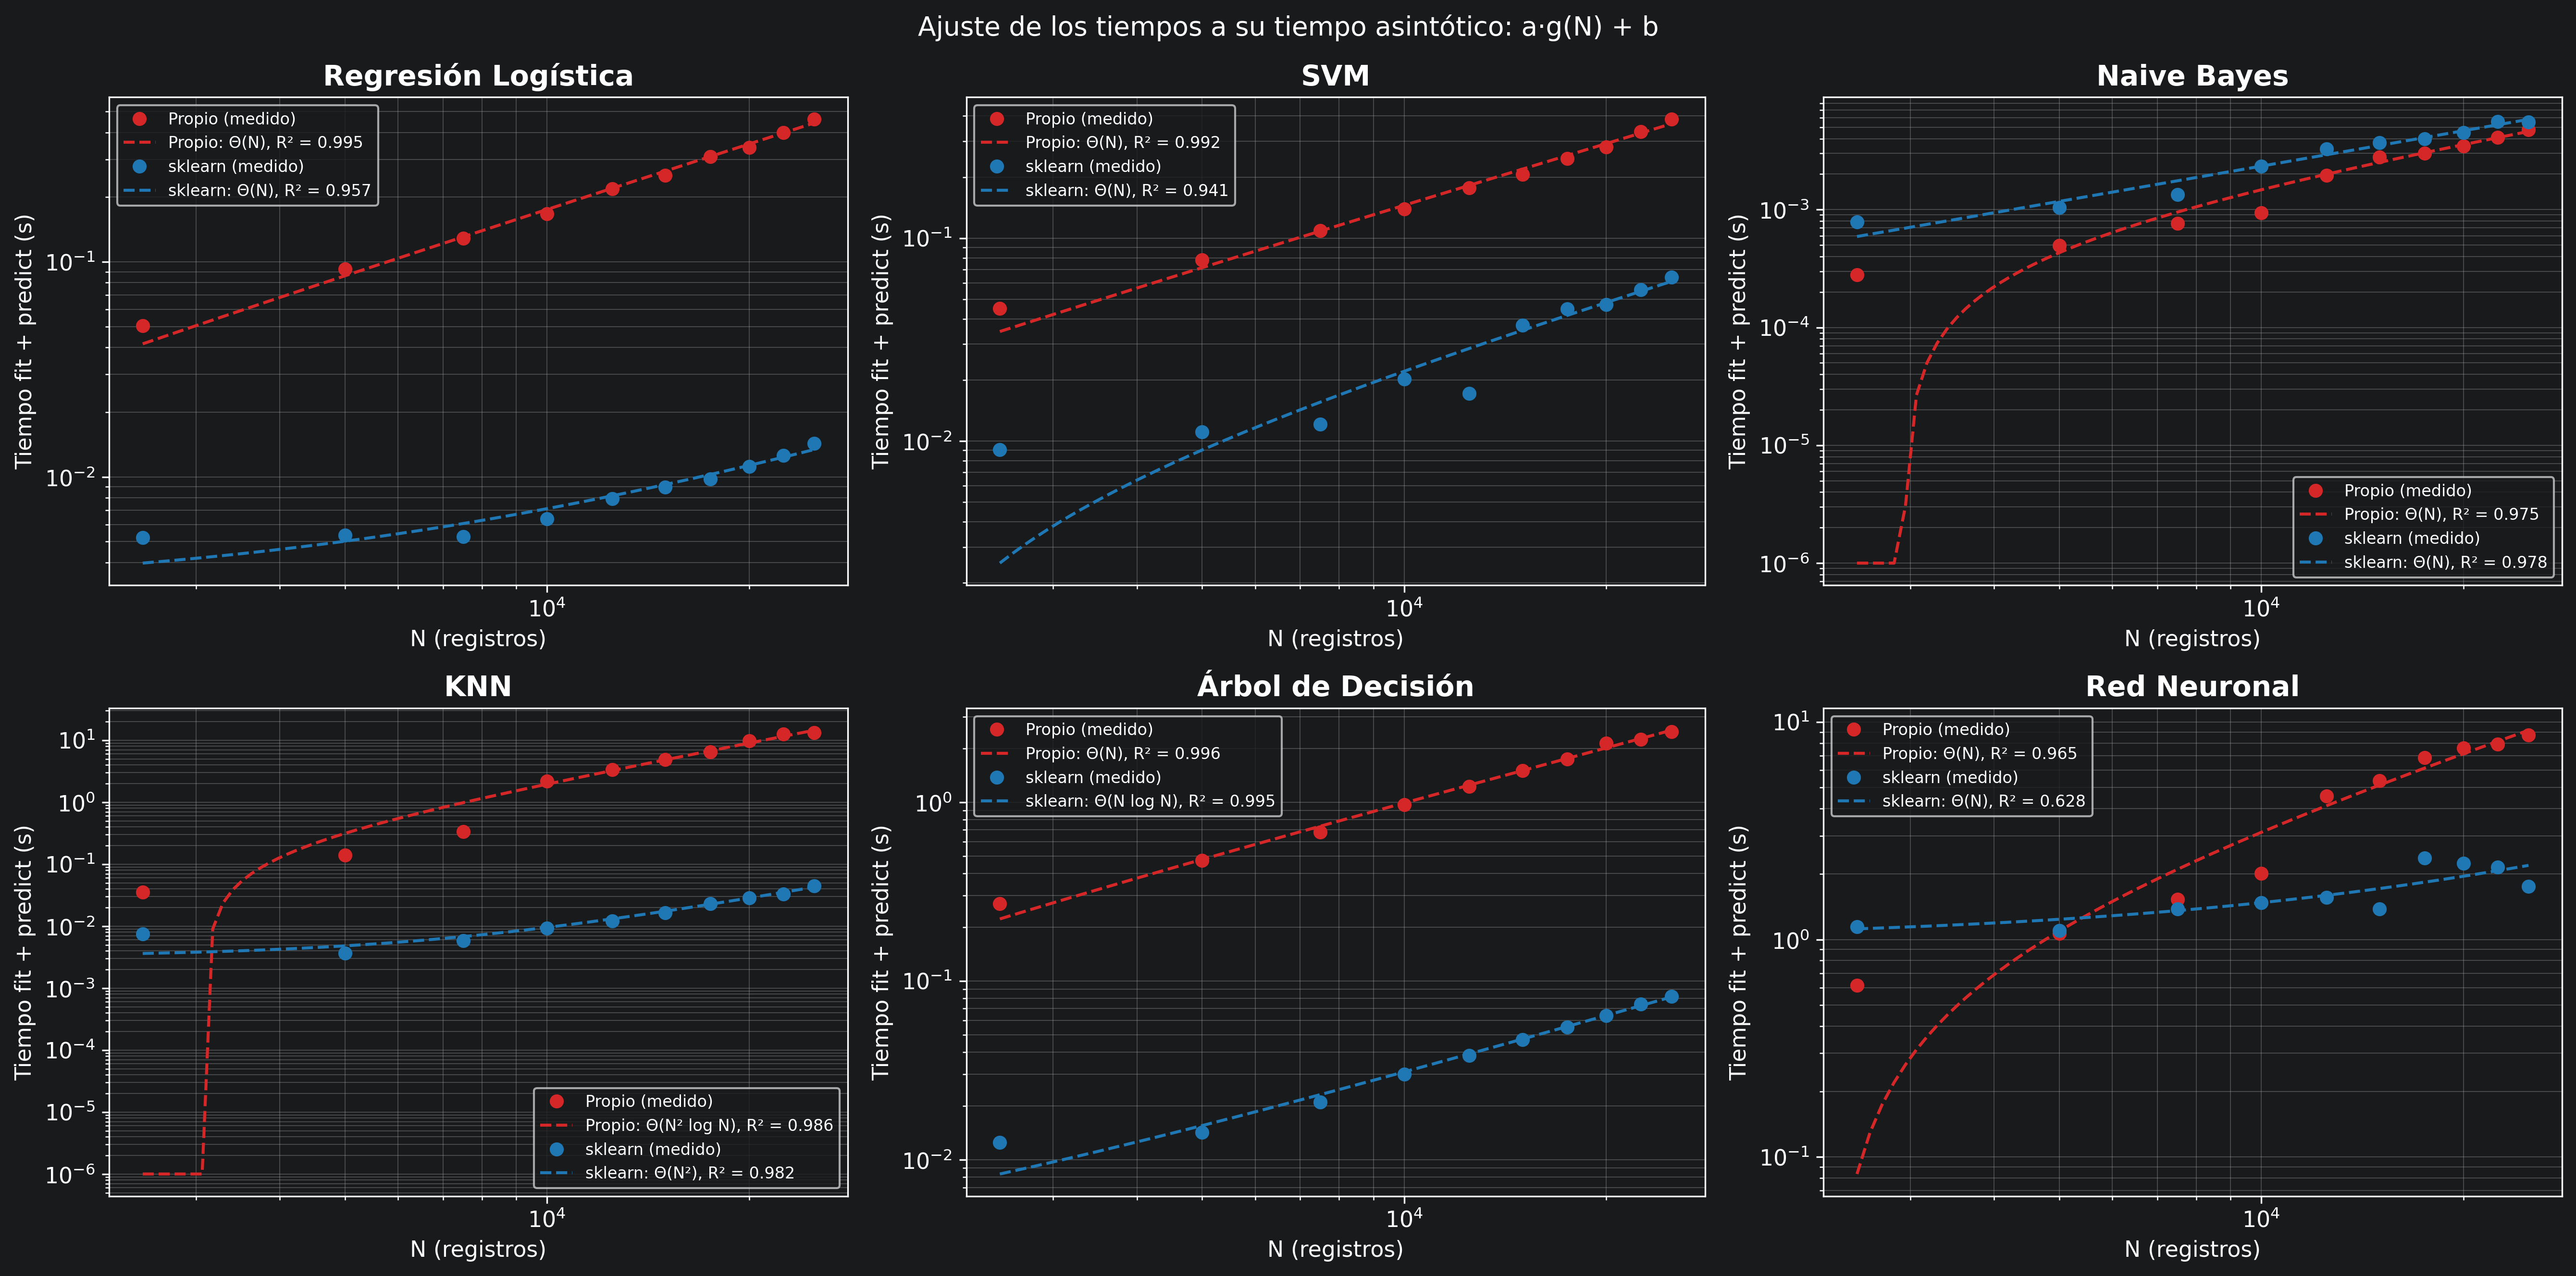

In [ ]:
tamanos = np.array([int(N_TOTAL * p / 100) for p in porcentajes], dtype=float)

formas = {
    "N": lambda n: n,
    "N log N": lambda n: n * np.log(n),
    "N²": lambda n: n ** 2,
    "N² log N": lambda n: n ** 2 * np.log(n),
}

asintotico_propio = {
    "Regresión Logística": "N",
    "SVM": "N",
    "Naive Bayes": "N",
    "KNN": "N² log N",
    "Árbol de Decisión": "N",
    "Red Neuronal": "N",
}
asintotico_sklearn = {
    "Regresión Logística": "N",
    "SVM": "N",
    "Naive Bayes": "N",
    "KNN": "N²",
    "Árbol de Decisión": "N log N",
    "Red Neuronal": "N",
}


def ajustar_tiempo(n, t, forma):
    """Ajusta t = a·g(n) + b por mínimos cuadrados con MultipleLinearRegression de utilities.
    g se divide entre su máximo para que XᵀX no quede mal condicionada."""
    g = formas[forma](n)
    escala = g.max()
    X = (g / escala).reshape(-1, 1)
    modelo = utils.MultipleLinearRegression().fit(X, t)
    return modelo.weights[0] / escala, modelo.bias, modelo.score(X, t)   # a, b, R²


def exponente_empirico(n, t):
    """Pendiente k de ln t = ln c + k·ln n."""
    modelo = utils.MultipleLinearRegression().fit(np.log(n).reshape(-1, 1), np.log(t))
    return modelo.weights[0]


def mejor_forma(n, t):
    r2_formas = {f: ajustar_tiempo(n, t, f)[2] for f in formas}
    mejor = max(r2_formas, key=r2_formas.get)
    return mejor, r2_formas[mejor]


filas = []
for origen, tabla, teorico in [("Propios", tiempos, asintotico_propio), ("sklearn", tiempos_sk, asintotico_sklearn)]:
    for nombre, t in tabla.items():
        t = np.array(t)
        a, b, r2 = ajustar_tiempo(tamanos, t, teorico[nombre])
        mejor, r2_mejor = mejor_forma(tamanos, t)
        filas.append({
            "Origen": origen,
            "Modelo": nombre,
            "Asintótico": f"Θ({teorico[nombre]})",
            "a (s)": a,
            "b (s)": b,
            "R²": r2,
            "Mejor forma": mejor,
            "R² mejor": r2_mejor,
            "k empírico": exponente_empirico(tamanos, t),
        })

df_ajuste = pd.DataFrame(filas)
display(df_ajuste.round({"R²": 4, "R² mejor": 4, "k empírico": 3}))

# Gráfica de puntos medidos y curva ajustada, propios vs sklearn
n_fino = np.linspace(tamanos.min(), tamanos.max(), 200)
fig, axes = plt.subplots(2, 3, figsize=(18, 9), dpi=300)

for ax, nombre in zip(axes.flatten(), tiempos.keys()):
    for origen, tabla, teorico, color in [
        ("Propio", tiempos, asintotico_propio, "#d62728"),
        ("sklearn", tiempos_sk, asintotico_sklearn, "#1f77b4"),
    ]:
        forma = teorico[nombre]
        a, b, r2 = ajustar_tiempo(tamanos, np.array(tabla[nombre]), forma)
        ax.plot(tamanos, tabla[nombre], "o", color=color, label=f"{origen} (medido)")
        ax.plot(n_fino, np.clip(a * formas[forma](n_fino) + b, 1e-6, None), "--", color=color,
                label=f"{origen}: Θ({forma}), R² = {r2:.3f}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(nombre)
    ax.set_xlabel("N (registros)")
    ax.set_ylabel("Tiempo fit + predict (s)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, which="both")

fig.suptitle("Ajuste de los tiempos a su tiempo asintótico: a·g(N) + b")
plt.tight_layout()
plt.savefig("7_ajuste_asintotico.png", dpi=300, bbox_inches="tight")
plt.show()


## Optimizaciones de la librería y su impacto en el escalamiento

Lo que hace sklearn distinto de `utilities.py`, algoritmo por algoritmo:

| Algoritmo | Optimización de sklearn | Efecto esperado en el escalamiento |
|---|---|---|
| KNN | `algorithm="auto"` elige la estructura según los datos: KD-tree o Ball-tree con pocas variables, fuerza bruta con muchas (en el código de sklearn, más de 15 variables o k ≥ n/2 → `brute`). En fuerza bruta calcula las distancias con ‖a−b‖² = ‖a‖² + ‖b‖² − 2·a·b, o sea un producto matricial BLAS por bloques en código compilado. Elige los k menores con selección parcial (Θ(n) por consulta) en lugar de ordenar todo (Θ(n·log n)). Puede repartir consultas entre núcleos con `n_jobs`. | Sigue siendo Θ(N²) con fuerza bruta, pero sin el factor log N y con una constante mucho menor. Con árboles baja a ≈ Θ(N·log N), pero la guía de usuario indica que con D > 20 se acerca a O(D·N) por consulta y deja de ganar. |
| Regresión Logística | L-BFGS (cuasi-Newton) con criterio de paro `tol`: converge en pocas iteraciones, en vez de las T = 2000 fijas del descenso de gradiente propio. | Cada iteración sigue costando Θ(n·d), pero el T efectivo es mucho menor. La pendiente en N sigue siendo 1. |
| SVM | `LinearSVC` usa liblinear (métodos de coordenadas / Newton), también con criterio de paro por tolerancia. | Mismo orden Θ(N), constante menor. El número de iteraciones puede crecer un poco con N. |
| Naive Bayes | Una sola pasada vectorizada por clase, sin copiar `X[y == c]` tres veces. | Θ(N), constante menor. |
| Árbol de Decisión | Implementado en Cython. Ordena cada variable una vez por nodo y evalúa todos los umbrales en una sola pasada con conteos acumulados, sin copiar submatrices. Documentación: O(n_features · n_samples · log n_samples). | El factor u·d del árbol propio (copiar `X[mask]` por cada umbral) desaparece: de Θ(P·u·d²·N) pasa a Θ(P·d·N·log N). |
| Red Neuronal | Minibatches (`batch_size = min(200, n)`), optimizador Adam y paro por `n_iter_no_change`. Los productos matriciales usan BLAS multihilo. | Cada época sigue siendo Θ(N·d·h), pero hay N/200 actualizaciones por época y el número de épocas lo decide la convergencia, no un T fijo. |
| General | Código compilado (C/Cython) y BLAS/LAPACK optimizados con SIMD, sin los bucles `for` de Python que tienen `KNNClassifier.predict` y `DecisionTreeClassifier.predict`. | Reduce la constante `a` del ajuste de la sección anterior, no el exponente. |

**Hipótesis que verifica la celda siguiente:**
1. En el KNN, buena parte de la diferencia con sklearn viene de la vectorización y de `argpartition`, no de la estructura de datos: `KNNOptimizado` (mismas ideas, escritas con NumPy) debería acercarse a `sklearn brute`.
2. Con d = 21 los árboles (`kd_tree`, `ball_tree`) no deberían ganarle a la fuerza bruta.
3. sklearn necesita muchas menos iteraciones que las T fijas del descenso de gradiente propio.


d = 21 variables -> algorithm='auto' eligió: brute



,Variante,k empírico,Mejor forma,R² mejor,Tiempo con N máx (s),Veces más rápido que el propio
0,KNN propio (argsort),2.785,N²,0.9872,13.3421,1.0
1,KNN propio optimizado,1.885,N²,0.9995,1.0318,12.9
2,sklearn brute,1.017,N² log N,0.9870,0.0423,315.5
3,sklearn kd_tree,1.832,N² log N,0.9946,1.2234,10.9
4,sklearn ball_tree,1.990,N² log N,0.9967,1.2673,10.5
5,sklearn auto,1.125,N²,0.9415,0.0432,309.0


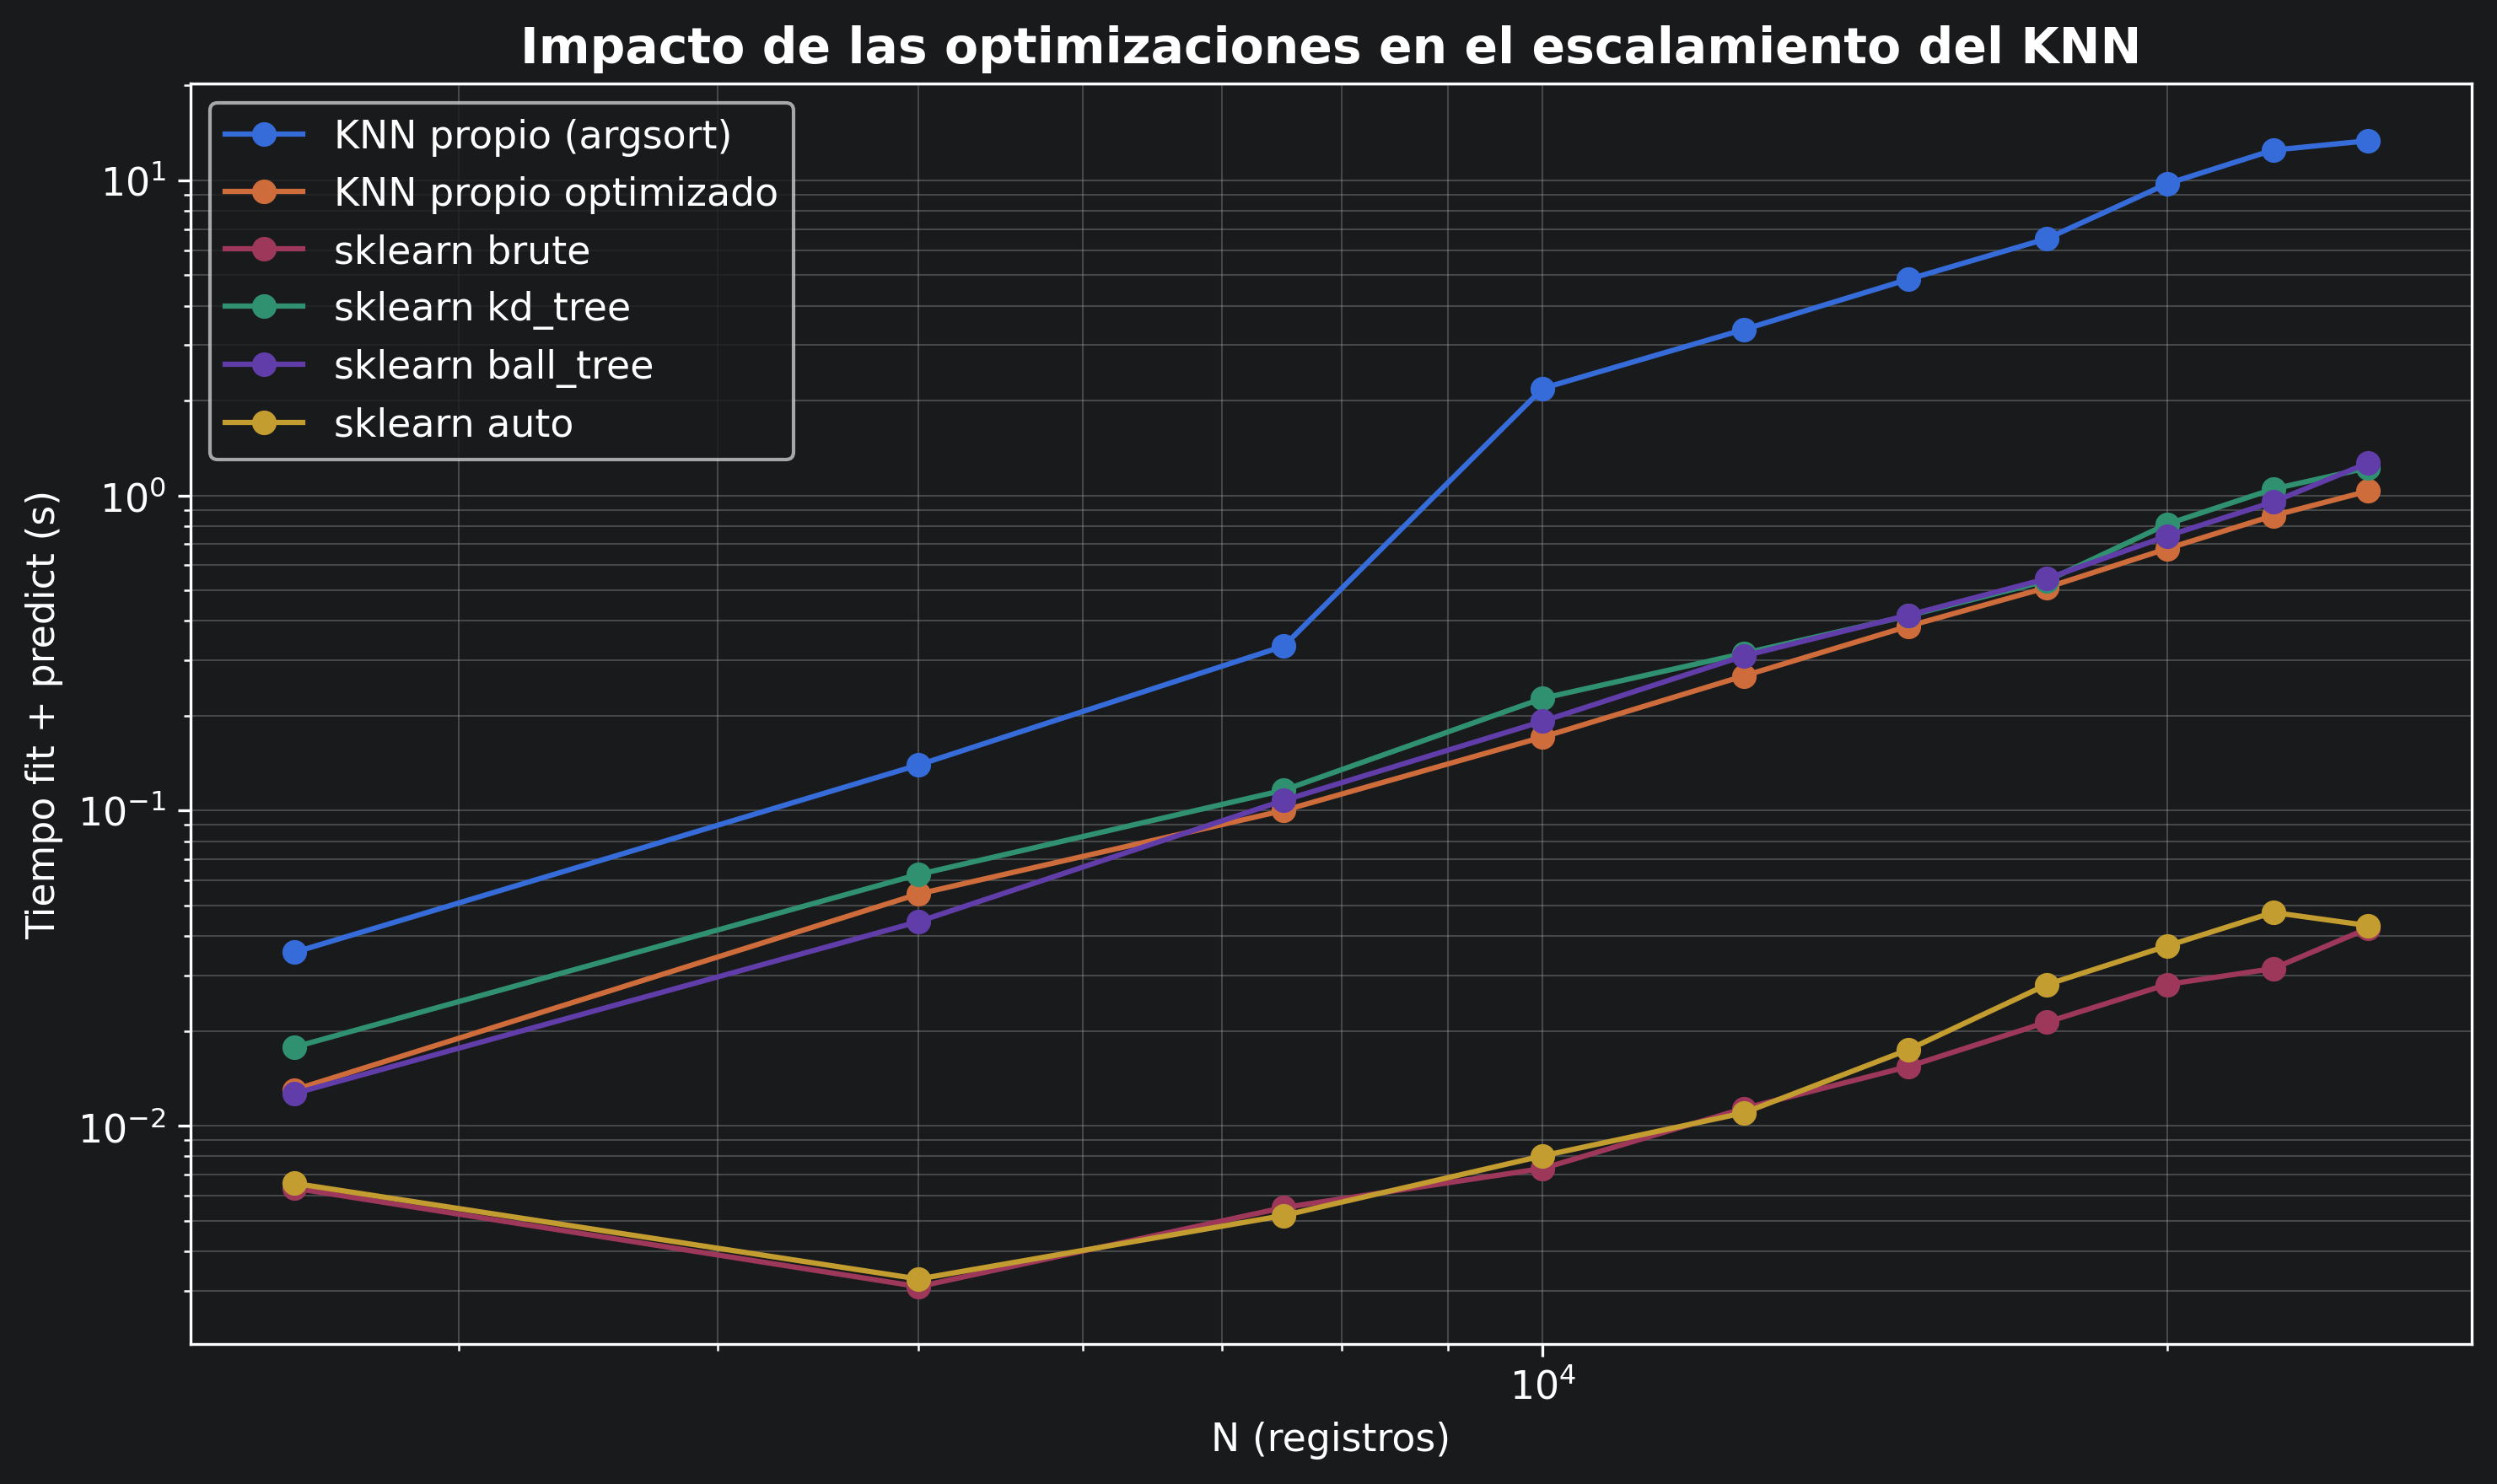

,N,Modelo,Iteraciones sklearn,T propio (fijas)
0,2500,Regresión Logística (lbfgs),20,2000
1,2500,SVM (LinearSVC),13,2000
2,2500,"Red Neuronal (MLP, adam)",816,1000
3,12500,Regresión Logística (lbfgs),16,2000
4,12500,SVM (LinearSVC),9,2000
5,12500,"Red Neuronal (MLP, adam)",184,1000
6,25000,Regresión Logística (lbfgs),16,2000
7,25000,SVM (LinearSVC),12,2000
8,25000,"Red Neuronal (MLP, adam)",228,1000


In [ ]:
N = np.array([int(N_TOTAL * p / 100) for p in porcentajes], dtype=float)

g_propio = {
    "Regresión Logística": N,
    "SVM": N,
    "Naive Bayes": N,
    "KNN": N ** 2 * np.log(N),
    "Árbol de Decisión": N,
    "Red Neuronal": N,
}

g_sk = {
    "Regresión Logística": N,
    "SVM": N,
    "Naive Bayes": N,
    "KNN": N ** 2,
    "Árbol de Decisión": N * np.log(N),
    "Red Neuronal": N,
}

fig, axes = plt.subplots(2, 3, figsize = (15, 8))

axes = axes.flatten()

for i, nombre in enumerate(tiempos):

    for origen, tabla, g in [("Propio", tiempos, g_propio), ("sklearn", tiempos_sk, g_sk)]:

        t = np.array(tabla[nombre])
        x = (g[nombre] / g[nombre].max()).reshape(-1, 1)
        modelo = utils.MultipleLinearRegression().fit(x, t)

        modelo_k = utils.MultipleLinearRegression().fit(np.log(N).reshape(-1, 1), np.log(t))

        a = modelo.weights[0] / g[nombre].max()

        print(f"{origen} - {nombre}: a = {a:.3e} | b = {modelo.bias:.4f} | R2: {modelo.score(x, t):.4f} | k = {modelo_k.weights[0]:.2f}")

        axes[i].plot(N, t, "o", label = f"{origen} medido")

        axes[i].plot(N, modelo.predict(x), "--", label = f"{origen} a*g(N) + b")

    axes[i].set_title(nombre)
    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    axes[i].legend()

fig.supxlabel("N")
fig.supylabel("Tiempo (s)")
plt.tight_layout()
plt.show()




class KNNOptimizado(utils.KNNClassifier):
    def predict(self, X):
        normas = (self.X_train ** 2).sum(axis = 1)
        pred = []
        for i in range(0, len(X), 500):
            B = X[i:i + 500]
            d2 = (B ** 2).sum(axis = 1)[:, None] + normas - 2 * B @ self.X_train.T

            vecinos = np.argpartition(d2, self.n_neighbors, axis = 1)[:, :self.n_neighbors]

            pred.append(self.y_train[vecinos].mean(axis = 1) > 0.5)
        return np.concatenate(pred).astype(int)

variantes_knn = {
    "KNN propio optimizado": KNNOptimizado(n_neighbors = 5),
    "sklearn brute": neighbors.KNeighborsClassifier(n_neighbors = 5, algorithm = "brute"),
    "sklearn kd_tree": neighbors.KNeighborsClassifier(n_neighbors = 5, algorithm = "kd_tree"),
    "sklearn ball_tree": neighbors.KNeighborsClassifier(n_neighbors = 5, algorithm = "ball_tree"),
    "sklearn auto": neighbors.KNeighborsClassifier(n_neighbors = 5),
}

tiempos_knn = {"KNN propio": tiempos["KNN"]}

for nombre in variantes_knn:
    tiempos_knn[nombre] = []

for p in porcentajes:
    n = int(N_TOTAL * p / 100)

    X_tr, X_te, y_tr, y_te = utils.train_test_split(
        X_esc[:n],
        y_all[:n],
        test_size = 0.2,
        seed = 0)

    for nombre, modelo in variantes_knn.items():
        tiempos_knn[nombre].append(medir(lambda: (modelo.fit(X_tr, y_tr), modelo.predict(X_te))))

for nombre, t in tiempos_knn.items():

    plt.plot(N, t, marker = "o", label = nombre)

    print(f"{nombre}: tiempo con N max = {t[-1]:.4f} s | {tiempos_knn['KNN propio'][-1] / t[-1]:.1f}x mas rapido que el propio")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("N (registros)")
plt.ylabel("Tiempo fit + predict (s)")
plt.title("Optimizaciones del KNN")
plt.legend()
plt.show()

for p in [1, 5, 10]:
    n = int(N_TOTAL * p / 100)
    X_tr, X_te, y_tr, y_te = utils.train_test_split(
        X_esc[:n],
        y_all[:n],
        test_size = 0.2,
        seed = 0)

    modelos_iter = [
        ("Regresion Logistica", linear_model.LogisticRegression(max_iter = 2000), 2000),
        ("SVM", svm.LinearSVC(C = 100.0), 2000),
        ("Red Neuronal", neural_network.MLPClassifier(hidden_layer_sizes = (16,), max_iter = 2000), 1000),
    ]
    for nombre, modelo, T in modelos_iter:
        modelo.fit(X_tr, y_tr)
        print(f"N = {n:>6} | {nombre}: sklearn {int(np.max(modelo.n_iter_))} iteraciones | propio {T} fijas")

In [ ]:
import platform, sklearn
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Procesador:", platform.processor(), "| núcleos lógicos:", os.cpu_count())
try:
    import psutil
    print(f"RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
except ImportError:
    print("RAM: instala psutil (pip install psutil) o consúltala en la configuración del equipo")

tabla_tiempos = pd.DataFrame(
    {**{f"{n} (propio)": t for n, t in tiempos.items()}, **{f"{n} (sklearn)": t for n, t in tiempos_sk.items()}},
    index=tamanos.astype(int),
)
display(tabla_tiempos.round(4))


Python: 3.14.3 | NumPy: 2.4.3 | scikit-learn: 1.9.1
Procesador: Intel64 Family 6 Model 198 Stepping 2, GenuineIntel | núcleos lógicos: 10
RAM: 34.0 GB


,Regresión Logística (propio),SVM (propio),Naive Bayes (propio),KNN (propio),Árbol de Decisión (propio),Red Neuronal (propio),Regresión Logística (sklearn),SVM (sklearn),Naive Bayes (sklearn),KNN (sklearn),Árbol de Decisión (sklearn),Red Neuronal (sklearn)
2500,0.0506,0.0451,0.0003,0.0355,0.2703,0.6141,0.0052,0.0090,0.0008,0.0075,0.0125,1.1455
5000,0.0928,0.0781,0.0005,0.1396,0.4711,1.0679,0.0054,0.0111,0.0010,0.0036,0.0143,1.0998
7500,0.1289,0.1088,0.0008,0.3325,0.6815,1.5305,0.0053,0.0121,0.0013,0.0058,0.0210,1.3782
10000,0.1671,0.1393,0.0009,2.1867,0.9676,2.0076,0.0064,0.0202,0.0023,0.0092,0.0300,1.4759
12500,0.2189,0.1770,0.0020,3.3590,1.2280,4.5599,0.0079,0.0171,0.0033,0.0122,0.0383,1.5588
15000,0.2531,0.2064,0.0028,4.8439,1.5058,5.3680,0.0089,0.0373,0.0037,0.0163,0.0469,1.3800
17500,0.3092,0.2474,0.0030,6.5240,1.7443,6.8450,0.0098,0.0448,0.0040,0.0229,0.0551,2.3672
20000,0.3399,0.2815,0.0035,9.7415,2.1347,7.6087,0.0112,0.0470,0.0045,0.0288,0.0640,2.2366
22500,0.4000,0.3355,0.0041,12.4633,2.2490,7.9075,0.0126,0.0557,0.0056,0.0328,0.0741,2.1504
25000,0.4600,0.3851,0.0047,13.3421,2.4794,8.7019,0.0143,0.0640,0.0056,0.0450,0.0818,1.7580


## Referencias

- scikit-learn, *User Guide: Nearest Neighbors* (elección de `algorithm`, costo de fuerza bruta, KD-tree y Ball-tree): https://scikit-learn.org/stable/modules/neighbors.html
- scikit-learn, *User Guide: Decision Trees*, sección Complexity (O(n_features · n_samples · log n_samples)): https://scikit-learn.org/stable/modules/tree.html#complexity
- scikit-learn, *Computational Performance*: https://scikit-learn.org/stable/computing/computational_performance.html
- scikit-learn, `euclidean_distances` (distancias con producto punto: ‖a−b‖² = ‖a‖² + ‖b‖² − 2·a·b): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.euclidean_distances.html
- NumPy, `numpy.argpartition`: https://numpy.org/doc/stable/reference/generated/numpy.argpartition.html
